<a href="https://colab.research.google.com/github/aya119119/Android-Mobile-App-/blob/main/MosquitoVision_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🦟 MosquitoVision AI
## A CNN-powered mosquito genus identification system for public-health surveillance

**Notebook:** `MosquitoVision_AI.ipynb` · **Framework:** PyTorch · **Platform:** Google Colab · **Dataset:** MosqVision-3K (Zenodo, DOI 10.5281/zenodo.14238701)

---

### What this notebook does

It takes you from *nothing* to a working research prototype:

| Phase | What happens | Main output |
|---|---|---|
| **0 – Setup & data download** | Mount Drive, create folders, **download the dataset from Zenodo straight into your Drive**, extract it | Dataset in Drive |
| **1 – Understand the data** | Count images, gallery, corrupted-file check, sizes/formats, **duplicate & near-duplicate detection** | Tables, plots, dataset summary |
| **2 – Preprocessing** | Resize to 128×128, scale to [0,1], encode labels, **leak-free 70/15/15 split**, augmentation (train only) | Three clean datasets |
| **3 – Custom CNN** | Build the CNN yourself in PyTorch, diagram, parameter count, forward-pass test | `MosquitoCNN` |
| **4 – Training** | Training/validation loops, history, overfitting diagnosis, improvement experiments, checkpoints | Best model `.pth`, curves, experiment log |
| **5 – Scientific evaluation** | Test set, precision/recall/F1, confusion matrix, error analysis, confidence threshold chosen on validation data | Evaluation report |
| **6 – Application** | Save model, inference function, Streamlit app, README, requirements | `app/app.py` |
| **Extensions** | Grad-CAM, pretrained benchmark, robustness test, dashboard notes | Optional |

### How to use it

1. **Runtime → Change runtime type → T4 GPU** (training also works on CPU, just slower).
2. Run cells **top to bottom**. Phase 0 downloads the data into your Google Drive (~57 MB), so the first milestone is already started for you.
3. Every cell is safe to re-run: downloads/extractions are skipped if the files already exist, so a Colab disconnect doesn't cost you your progress.

### ⚠️ Scientific boundaries (keep these in your report)

1. **Identification ≠ pathogen detection.** A photograph cannot show whether a mosquito carries malaria parasites or dengue virus.
2. **Genus ≠ species.** The model predicts *Aedes*, *Anopheles* or *Culex* only.
3. **A prediction is not a confirmed identification.** Uncertain cases need expert verification.
4. **The dataset is not Moroccan-specific.** A local deployment would need local data and validation.
5. **High test accuracy ≠ real-world effectiveness.** Different cameras, backgrounds and lighting must be tested.

These are not weaknesses to hide, they are research questions this project investigates.

---
# 🚀 Phase 0 — Environment setup and dataset download

**Goal:** get a reproducible workspace and the raw data into Google Drive *before* any modelling.

**Why Google Drive?** Colab's local disk is wiped when the runtime disconnects. Anything stored under `/content/drive/MyDrive/` survives. We keep the ZIP, extracted images, cached arrays, trained weights and results there.

**Why check the archive before extracting?** We never assume the folder layout. Zenodo archives sometimes contain nested folders, macOS junk (`__MACOSX`), or pre-made train/test folders. We inspect first, then write code that finds the class folders wherever they are.

**What you'll see:** GPU info, a mounted Drive, the folder tree, the download progress bar, the archive listing, and the located class folders.

In [28]:
# Cell 0.1 — Imports, reproducibility and hardware check
import sys, os, json, time, random, shutil, zipfile, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

warnings.filterwarnings("ignore")

print("Python  :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (running on CPU - works, but slower)")

# Reproducibility: fix every random number generator we use
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Python  : 3.13.16
PyTorch : 2.14.1+cu130
GPU     : Tesla T4
Using device: cuda


### Cell 0.2 — Connect Google Drive
A pop-up asks you to authorise access. After this, Drive appears at `/content/drive`.

In [29]:
# Cell 0.2 — Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Cell 0.3 — Create the project folders
We follow the structure recommended in the roadmap, so the same layout can later become your GitHub repository.

```
MyDrive/MosquitoVision/
├── data/        ← ZIP, extracted images, cached arrays
├── notebooks/   ← (put a copy of this notebook here)
├── models/      ← trained weights (.pth) + inference config
├── results/     ← plots, reports, misclassified images
└── app/         ← Streamlit application
```

In [30]:
# Cell 0.3 — Create folders
PROJECT_DIR = Path("/content/drive/MyDrive/MosquitoVision")
DATA_DIR    = PROJECT_DIR / "data"
EXTRACT_DIR = DATA_DIR / "extracted"
MODELS_DIR  = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
APP_DIR     = PROJECT_DIR / "app"
NB_DIR      = PROJECT_DIR / "notebooks"

for d in [DATA_DIR, EXTRACT_DIR, MODELS_DIR, RESULTS_DIR, APP_DIR, NB_DIR, RESULTS_DIR / "incorrect_predictions"]:
    d.mkdir(parents=True, exist_ok=True)

print("Project folders created!")
for d in [DATA_DIR, MODELS_DIR, RESULTS_DIR, APP_DIR, NB_DIR]:
    print("  ", d)

Project folders created!
   /content/drive/MyDrive/MosquitoVision/data
   /content/drive/MyDrive/MosquitoVision/models
   /content/drive/MyDrive/MosquitoVision/results
   /content/drive/MyDrive/MosquitoVision/app
   /content/drive/MyDrive/MosquitoVision/notebooks


### Cell 0.4 — 📥 Download MosqVision-3K from Zenodo directly into Drive

The dataset record is `14238701` (≈ 56.8 MB). This cell:

1. Asks the **Zenodo API** which files the record contains (so we don't depend on a hard-coded file name that might change).
2. Falls back to the URL from the project brief if the API call fails.
3. Streams the file into `MosquitoVision/data/mosquito_dataset.zip` with a progress bar.
4. **Skips the download** if a valid ZIP is already there.
5. Verifies that the result is a real ZIP (a failed download often produces an HTML error page instead).

> 📌 **Dataset:** Masud (2024), *MosqVision-3K*, Zenodo, DOI 10.5281/zenodo.14238701. Check the reuse terms on the Zenodo page before redistributing the images.

In [31]:
# Cell 0.4 — Download the ZIP into Google Drive
import requests
from tqdm.auto import tqdm

ZIP_PATH       = DATA_DIR / "mosquito_dataset.zip"
ZENODO_RECORD  = "14238701"
FALLBACK_URL   = "https://zenodo.org/records/14238701/files/mosquito-dataset-for-classification-cnn.zip?download=1"

def resolve_download_url():
    """Ask Zenodo which files exist; fall back to the URL from the project brief."""
    try:
        r = requests.get(f"https://zenodo.org/api/records/{ZENODO_RECORD}", timeout=60)
        r.raise_for_status()
        files = r.json().get("files", [])
        print("Files listed in the Zenodo record:")
        for f in files:
            print(f"   - {f.get('key')}  ({f.get('size', 0)/1e6:.1f} MB)")
        zips = [f for f in files if str(f.get("key", "")).lower().endswith(".zip")]
        if zips:
            return zips[0]["links"]["self"], zips[0].get("size")
    except Exception as e:
        print("Could not query the Zenodo API:", e)
    return FALLBACK_URL, None

def download(url, dest, expected_size=None):
    tmp = Path(str(dest) + ".part")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) or expected_size
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc="Downloading") as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    os.replace(tmp, dest)

if ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH):
    print(f"ZIP already in Drive ({ZIP_PATH.stat().st_size/1e6:.1f} MB) - skipping download.")
else:
    url, size = resolve_download_url()
    print("\nDownloading from:", url)
    download(url, ZIP_PATH, size)

assert zipfile.is_zipfile(ZIP_PATH), "Downloaded file is not a valid ZIP - re-run this cell or download manually from Zenodo."
print(f"\n✅ Dataset ZIP ready: {ZIP_PATH}  ({ZIP_PATH.stat().st_size/1e6:.1f} MB)")

ZIP already in Drive (56.8 MB) - skipping download.

✅ Dataset ZIP ready: /content/drive/MyDrive/MosquitoVision/data/mosquito_dataset.zip  (56.8 MB)


### Cell 0.5 — Inspect the archive *before* extracting
We list the contents and count file types. This tells us the real layout (are there nested folders? other file types? pre-split train/test folders?).

In [32]:
# Cell 0.5 — Look inside the ZIP without extracting
from collections import Counter

with zipfile.ZipFile(ZIP_PATH) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]
    print(f"Total files in archive: {len(names)}\n")
    print("First 25 entries:")
    for n in names[:25]:
        print("  ", n)

ext_counts = Counter(Path(n).suffix.lower() for n in names)
print("\nFile extensions in archive:", dict(ext_counts))

Total files in archive: 3000

First 25 entries:
   Mosquito_dataset/AEDES/transformed_0001.jpg
   Mosquito_dataset/AEDES/transformed_0002.jpg
   Mosquito_dataset/AEDES/transformed_0003.jpg
   Mosquito_dataset/AEDES/transformed_0004.jpg
   Mosquito_dataset/AEDES/transformed_0005.jpg
   Mosquito_dataset/AEDES/transformed_0006.jpg
   Mosquito_dataset/AEDES/transformed_0007.jpg
   Mosquito_dataset/AEDES/transformed_0008.jpg
   Mosquito_dataset/AEDES/transformed_0009.jpg
   Mosquito_dataset/AEDES/transformed_0010.jpg
   Mosquito_dataset/AEDES/transformed_0011.jpg
   Mosquito_dataset/AEDES/transformed_0012.jpg
   Mosquito_dataset/AEDES/transformed_0013.jpg
   Mosquito_dataset/AEDES/transformed_0014.jpg
   Mosquito_dataset/AEDES/transformed_0015.jpg
   Mosquito_dataset/AEDES/transformed_0016.jpg
   Mosquito_dataset/AEDES/transformed_0017.jpg
   Mosquito_dataset/AEDES/transformed_0018.jpg
   Mosquito_dataset/AEDES/transformed_0019.jpg
   Mosquito_dataset/AEDES/transformed_0020.jpg
   Mosquito_

### Cell 0.6 — Extract into Drive
Extraction is skipped if images already exist. We ignore `__MACOSX` metadata folders.

In [33]:
# Cell 0.6 — Extract the archive
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def list_images(root):
    out = []
    for p in Path(root).rglob("*"):
        if p.is_file() and p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts and not p.name.startswith("._"):
            out.append(p)
    return sorted(out)

if len(list_images(EXTRACT_DIR)) > 0:
    print("Images already extracted - skipping extraction.")
else:
    print("Extracting (can take a minute on Drive)...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        members = [m for m in z.namelist() if "__MACOSX" not in m]
        for m in tqdm(members, desc="Extracting"):
            z.extract(m, EXTRACT_DIR)
    print("Done.")

print("Images found after extraction:", len(list_images(EXTRACT_DIR)))

Images already extracted - skipping extraction.
Images found after extraction: 3000


### Cell 0.7 — Locate the three class folders
We print the folder tree (3 levels deep) and then **infer each image's label from the nearest parent folder whose name contains `aedes`, `anopheles` or `culex`** (case-insensitive). This works even if the archive nests the folders (e.g. `train/Aedes/…`). If the archive already contained its own train/test folders, we simply merge everything: we will create our *own* leak-free split in Phase 2.

In [34]:
# Cell 0.7 — Show folder tree and infer labels
CLASS_NAMES = ["Aedes", "Anopheles", "Culex"]
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}

print("Folder tree (max depth 3):")
base_depth = len(EXTRACT_DIR.parts)
for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = len(Path(root).parts) - base_depth
    if depth > 3 or "__MACOSX" in root:
        continue
    n_img = sum(1 for f in files if Path(f).suffix.lower() in IMG_EXT)
    print("  " * depth + f"📁 {Path(root).name}/   ({n_img} images directly inside)")

def infer_label(path):
    rel_parts = path.relative_to(EXTRACT_DIR).parts[:-1]
    for part in reversed(rel_parts):
        for c in CLASS_NAMES:
            if c.lower() in part.lower():
                return c
    return None

all_images = list_images(EXTRACT_DIR)
labelled   = [(p, infer_label(p)) for p in all_images]
unlabelled = [p for p, l in labelled if l is None]
image_files = [(p, l) for p, l in labelled if l is not None]

print(f"\nImages with a recognised class folder: {len(image_files)}")
print(f"Images WITHOUT a recognised class     : {len(unlabelled)}")
if unlabelled:
    print("   examples:", [str(p.relative_to(EXTRACT_DIR)) for p in unlabelled[:5]])
assert len(image_files) > 0, "No class folders found - inspect the tree above and adapt infer_label()."

Folder tree (max depth 3):
📁 extracted/   (0 images directly inside)
  📁 Mosquito_dataset/   (0 images directly inside)
    📁 AEDES/   (1000 images directly inside)
    📁 ANOPHELES/   (1000 images directly inside)
    📁 CULEX/   (1000 images directly inside)

Images with a recognised class folder: 3000
Images WITHOUT a recognised class     : 0


---
# 🔍 Phase 1 — Understand the problem and explore the dataset
*(Roadmap: Days 1–2)*

**Main objective:** understand exactly what the CNN is supposed to learn **before** writing a single layer. Bad data silently produces bad models, so we audit the data first.

### Background you need

**The three groups and their public-health relevance**

| Group | Examples of associated diseases |
|---|---|
| *Aedes* | Dengue, Zika, chikungunya, yellow fever |
| *Anopheles* | Malaria (transmitted by infected females) |
| *Culex* | West Nile fever, Japanese encephalitis |

These are *associations*, not proof that every member of a genus transmits every disease.

**What an image is to a computer.** A colour photo is a grid of pixels; each pixel has Red, Green and Blue values from 0 to 255. A label (here: the folder name) says what the photo shows.

**What we are asking the model to learn.** This is a *supervised* (labels exist), *multi-class* (three possible answers), *classification* (pick the most likely one) problem.

### What this phase does, step by step

1. **One pass over every file** to record: label, format, colour mode, width, height, brightness, an MD5 fingerprint (finds *exact* copies) and a 64-bit perceptual hash (finds *near-identical* images).
2. **Class count table + bar chart** – is the dataset balanced?
3. **Gallery of sample images** – look at the data with your own eyes.
4. **Corruption check** – unreadable or tiny files.
5. **Size / format / brightness per class** – *shortcut detection*: if one class was photographed with a different camera or resolution, the CNN might learn "image size" instead of "mosquito". Because MosqVision-3K merges several sources, this check matters.
6. **Duplicate and near-duplicate detection** – if the same photo ends up in both training and test sets, test accuracy is fake. We also detect the same image appearing under *two different labels* (a labelling error).
7. **Auto-generated dataset summary** you can paste into your report.

### Cell 1.1 — Build the metadata table (one pass over all images)
**Perceptual hash (dHash):** shrink the image to 9×8 grey pixels and record whether each pixel is brighter than its right-hand neighbour → 64 bits. Two visually near-identical photos give hashes that differ in only a few bits, even after resizing or re-compression. We store the result in Drive so a reconnect doesn't force a re-scan.

In [35]:
# Cell 1.1 — Scan every image once and collect metadata + fingerprints
from tqdm.auto import tqdm

META_PATH = DATA_DIR / "metadata.pkl"

def dhash_bits(img, size=8):
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().astype(np.uint8)   # 64 bits

def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

if META_PATH.exists():
    df = pd.read_pickle(META_PATH)
    print("Loaded cached metadata:", len(df), "rows")
else:
    rows = []
    for p, label in tqdm(image_files, desc="Scanning images"):
        rec = dict(path=str(p), label=label, ok=True, error="", format=None, mode=None,
                   width=0, height=0, brightness=np.nan, md5=None, dhash=None)
        try:
            rec["md5"] = md5_of(p)
            with Image.open(p) as im:
                rec["format"], rec["mode"] = im.format, im.mode
                rec["width"], rec["height"] = im.size
                im.load()                                  # forces full decode -> detects truncated files
                rec["dhash"] = dhash_bits(im)
                rec["brightness"] = float(np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32).mean())
        except Exception as e:
            rec["ok"], rec["error"] = False, repr(e)
        rows.append(rec)
    df = pd.DataFrame(rows)
    df.to_pickle(META_PATH)
    print("Scan finished and cached to Drive.")

df["min_side"] = df[["width", "height"]].min(axis=1)
print(df[["label", "ok", "format", "mode", "width", "height"]].head())

Loaded cached metadata: 3000 rows
   label    ok format mode  width  height
0  Aedes  True   JPEG  RGB    224     224
1  Aedes  True   JPEG  RGB    224     224
2  Aedes  True   JPEG  RGB    224     224
3  Aedes  True   JPEG  RGB    224     224
4  Aedes  True   JPEG  RGB    224     224


### Cell 1.2 — Class counts
**Deliverable: a table with the image count of every class.** We look at the absolute counts, the percentage, and whether the classes are balanced. Balanced classes make plain accuracy meaningful; with imbalance you must rely on per-class recall/F1.

,images,percent
label,,
Aedes,1000,33.3
Anopheles,1000,33.3
Culex,1000,33.3


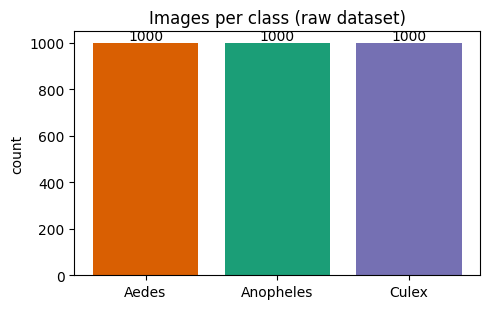

In [36]:
# Cell 1.2 — Image counts per class
counts = df.groupby("label").size().reindex(CLASS_NAMES).rename("images").to_frame()
counts["percent"] = (100 * counts["images"] / counts["images"].sum()).round(1)
display(counts)

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(counts.index, counts["images"], color=["#d95f02", "#1b9e77", "#7570b3"])
ax.bar_label(bars)
ax.set_title("Images per class (raw dataset)")
ax.set_ylabel("count")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_distribution_raw.png", dpi=150)
plt.show()

### Cell 1.3 — Gallery of sample images
**Deliverable: a gallery of 15–20 images.** Don't skip this. Look for: Is the mosquito centred and large? Are there rulers, hands, labels, petri dishes, white backgrounds or lab trays? Do the classes look like they were photographed in *different* conditions? Anything you spot here (a particular background in only one class) is a potential shortcut the CNN could exploit. Re-run the cell to see a different random sample.

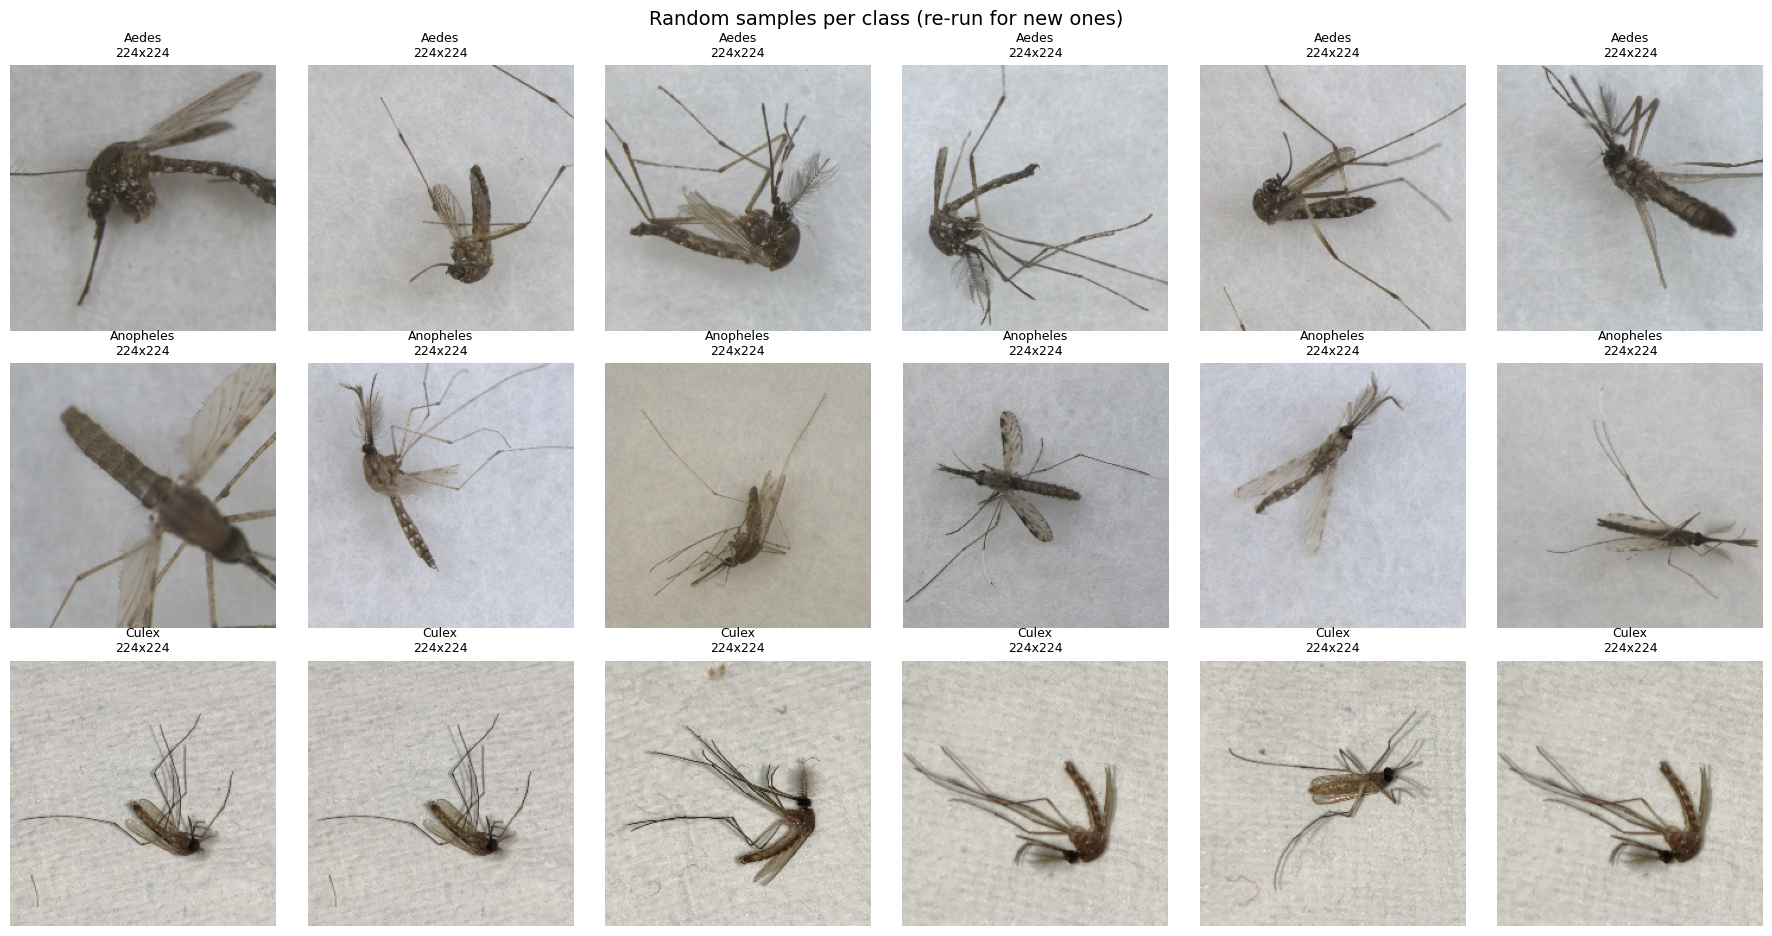

In [37]:
# Cell 1.3 — 3 rows (one per class) x 6 random samples
rng = np.random.default_rng()
fig, axes = plt.subplots(3, 6, figsize=(18, 9.5))
for r, cls in enumerate(CLASS_NAMES):
    sub = df[(df.label == cls) & df.ok]
    pick = sub.sample(6, random_state=int(rng.integers(0, 10_000)))
    for c, (_, row) in enumerate(pick.iterrows()):
        ax = axes[r, c]
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(f"{cls}\n{row.width}x{row.height}", fontsize=9)
        ax.axis("off")
plt.suptitle("Random samples per class (re-run for new ones)", fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_gallery.png", dpi=120)
plt.show()

### Cell 1.4 — Corrupted / unusable images, formats and colour modes
* **Unreadable files** would crash training half-way through; we find them now.
* **Very small images** (shortest side < 64 px) contain too little detail to be useful.
* **Colour mode** matters: grayscale (`L`) or RGBA/palette (`P`) images must be converted to 3-channel RGB so every sample has the same shape.

In [38]:
# Cell 1.4 — Integrity, format and mode check
bad = df[~df.ok]
print(f"Unreadable/corrupted files: {len(bad)}")
if len(bad):
    display(bad[["path", "label", "error"]].head(10))

tiny = df[df.ok & (df.min_side < 64)]
print(f"Very small images (<64 px shortest side): {len(tiny)}")

print("\nImage formats:")
display(pd.crosstab(df.label, df.format.fillna("unreadable")))
print("Colour modes:")
display(pd.crosstab(df.label, df["mode"].fillna("unreadable")))

Unreadable/corrupted files: 0
Very small images (<64 px shortest side): 0

Image formats:


format,JPEG
label,
Aedes,1000
Anopheles,1000
Culex,1000


Colour modes:


mode,RGB
label,
Aedes,1000
Anopheles,1000
Culex,1000


### Cell 1.5 — Dimensions, brightness and the "shortcut" check
If the **size or brightness distributions differ a lot between classes**, a CNN could reach good accuracy by recognising the *source* of the photos (camera, lab, website) rather than the mosquito. Heavy overlap = reassuring. Clear separation = a warning to mention in your limitations, and a reason to test on images from other sources later.

label              Aedes  Anopheles   Culex
width      count  1000.0     1000.0  1000.0
           mean    224.0      224.0   224.0
           std       0.0        0.0     0.0
           min     224.0      224.0   224.0
           25%     224.0      224.0   224.0
           50%     224.0      224.0   224.0
           75%     224.0      224.0   224.0
           max     224.0      224.0   224.0
height     count  1000.0     1000.0  1000.0
           mean    224.0      224.0   224.0
           std       0.0        0.0     0.0
           min     224.0      224.0   224.0
           25%     224.0      224.0   224.0
           50%     224.0      224.0   224.0
           75%     224.0      224.0   224.0
           max     224.0      224.0   224.0
brightness count  1000.0     1000.0  1000.0
           mean    173.6      174.7   191.9
           std      15.6       14.8     2.2
           min     128.5      129.9   188.0
           25%     165.2      164.5   190.2
           50%     174.5      173.3   190.8
           75%     184.6      186.1   194.2
           max     211.0      222.3   195.2

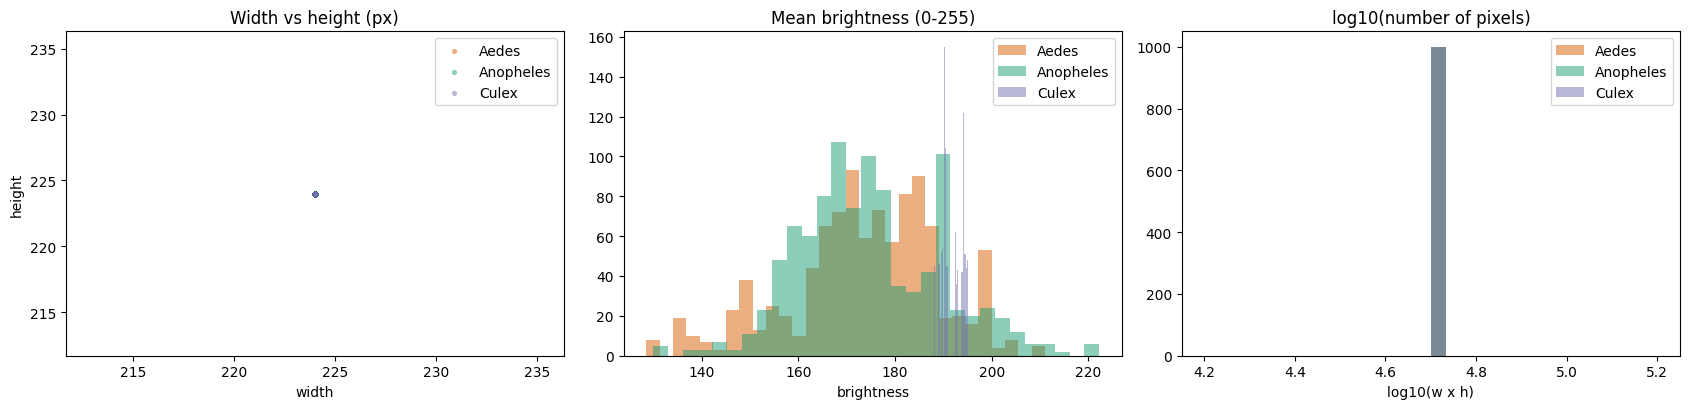

In [39]:
# Cell 1.5 — Size & brightness per class
ok = df[df.ok].copy()
display(ok.groupby("label")[["width", "height", "brightness"]].describe().round(1).T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
colors = {"Aedes": "#d95f02", "Anopheles": "#1b9e77", "Culex": "#7570b3"}
for cls in CLASS_NAMES:
    s = ok[ok.label == cls]
    axes[0].scatter(s.width, s.height, s=8, alpha=0.4, label=cls, color=colors[cls])
    axes[1].hist(s.brightness, bins=30, alpha=0.5, label=cls, color=colors[cls])
    axes[2].hist(np.log10(s.width * s.height), bins=30, alpha=0.5, label=cls, color=colors[cls])
axes[0].set(title="Width vs height (px)", xlabel="width", ylabel="height")
axes[1].set(title="Mean brightness (0-255)", xlabel="brightness")
axes[2].set(title="log10(number of pixels)", xlabel="log10(w x h)")
for a in axes: a.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "size_brightness_by_class.png", dpi=130)
plt.show()

### Cell 1.6 — Exact and near-duplicate detection (and cross-label conflicts)
**Why this is critical:** with scraped / merged datasets the same photo often appears several times. If one copy lands in *training* and another in *testing*, the model is graded on something it has already memorised, so accuracy is inflated and meaningless.

How it works:
1. **Exact duplicates:** identical MD5 file fingerprint.
2. **Near-duplicates:** perceptual-hash Hamming distance ≤ `NEAR_DUP_THRESHOLD` bits (out of 64). Computed for all pairs with a single matrix multiplication.
3. Duplicates are merged into **clusters** (union-find). Every image gets a `cluster_id`. In Phase 2 *whole clusters* are kept together in one split.
4. **Cross-label conflicts:** a cluster containing images from more than one class means the same picture carries different labels → at least one label is wrong. Those images are removed in Phase 2.

> The threshold is a trade-off. Lower = fewer false alarms, may miss slightly edited copies. Higher = catches more copies but may group genuinely different low-texture photos. Inspect the examples below and adjust if needed.

In [40]:
# Cell 1.6 — Duplicate clusters
NEAR_DUP_THRESHOLD = 4     # max differing bits (of 64) to call two images near-duplicates

df_ok = df[df.ok].reset_index(drop=True)
H = np.stack(df_ok["dhash"].values).astype(np.float32)             # (N, 64)
matches = H @ H.T + (1 - H) @ (1 - H).T                            # number of equal bits
dist = 64 - matches                                                 # Hamming distance matrix (N, N)

N = len(df_ok)
parent = list(range(N))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(i, j):
    ri, rj = find(i), find(j)
    if ri != rj:
        parent[rj] = ri

ii, jj = np.where(np.triu(dist <= NEAR_DUP_THRESHOLD, k=1))
for i, j in zip(ii, jj):
    union(int(i), int(j))
# exact duplicates are always in the same cluster as well
for _, idxs in df_ok.groupby("md5").groups.items():
    idxs = list(idxs)
    for k in idxs[1:]:
        union(idxs[0], k)

roots = np.array([find(i) for i in range(N)])
_, cluster_id = np.unique(roots, return_inverse=True)
df_ok["cluster_id"] = cluster_id
df_ok["cluster_size"] = df_ok.groupby("cluster_id")["path"].transform("count")
df_ok["cluster_n_labels"] = df_ok.groupby("cluster_id")["label"].transform("nunique")

n_exact = int(df_ok.duplicated("md5", keep="first").sum())
n_near_extra = int((df_ok.cluster_size > 1).sum() - df_ok[df_ok.cluster_size > 1].cluster_id.nunique())
n_conflict_imgs = int((df_ok.cluster_n_labels > 1).sum())

print(f"Images analysed                          : {N}")
print(f"Exact duplicate files (same MD5)         : {n_exact}")
print(f"Unique clusters                          : {df_ok.cluster_id.nunique()}")
print(f"Images that are redundant copies         : {n_near_extra}  (exact + near duplicates)")
print(f"Images in clusters with CONFLICTING labels: {n_conflict_imgs}")
print("\nCluster size distribution:")
display(df_ok.drop_duplicates("cluster_id").cluster_size.value_counts().sort_index().rename("n_clusters").to_frame())

Images analysed                          : 3000
Exact duplicate files (same MD5)         : 1919
Unique clusters                          : 1077
Images that are redundant copies         : 1923  (exact + near duplicates)
Images in clusters with CONFLICTING labels: 0

Cluster size distribution:


,n_clusters
cluster_size,
1,474
2,319
3,148
4,60
5,21
6,9
7,5
10,1
14,1


Largest duplicate clusters:


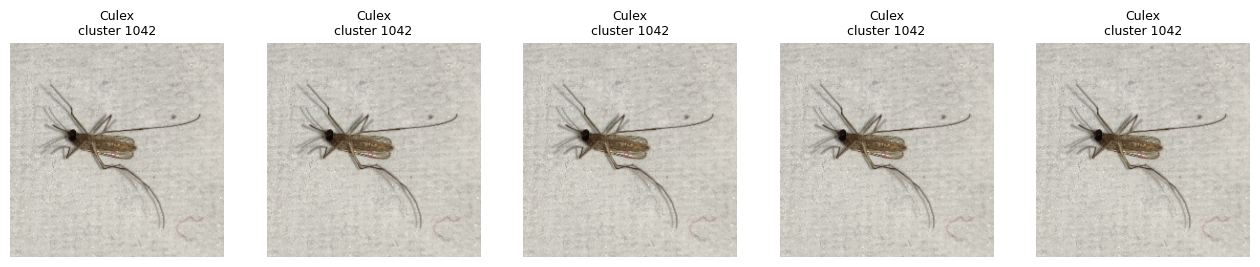

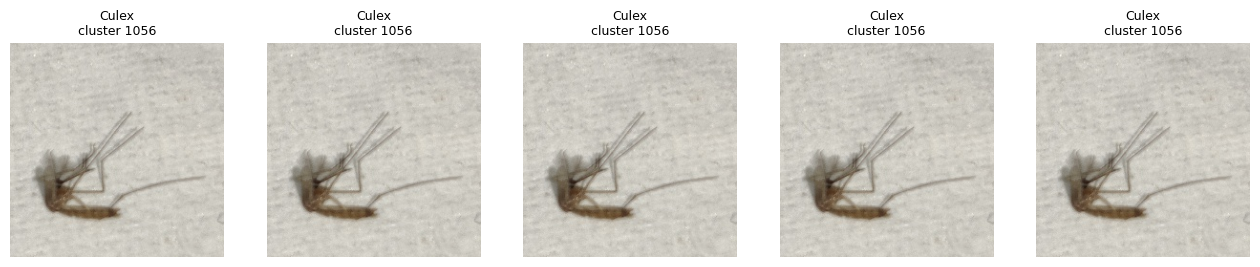

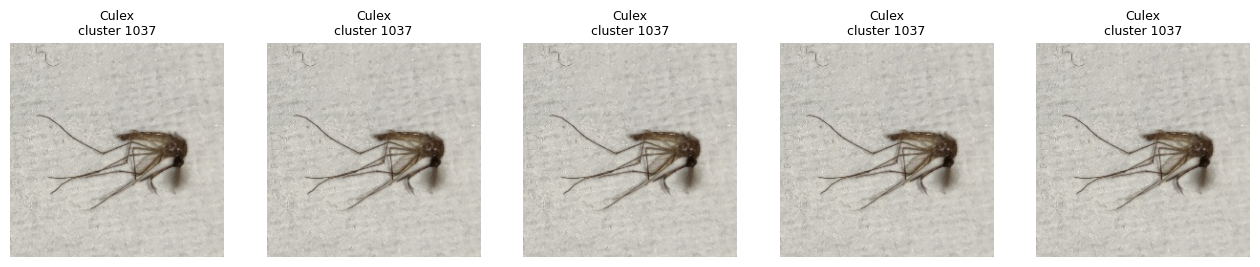

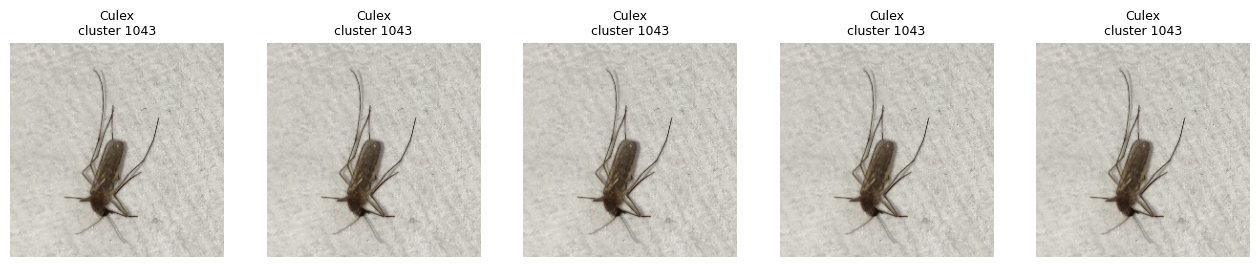


Clusters with conflicting labels: 0


In [41]:
# Cell 1.6b — Look at the largest duplicate clusters and any label conflicts
def show_cluster(cid, max_imgs=5):
    sub = df_ok[df_ok.cluster_id == cid].head(max_imgs)
    fig, axes = plt.subplots(1, len(sub), figsize=(3.2 * len(sub), 3.4))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, sub.iterrows()):
        ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
        ax.set_title(f"{r.label}\ncluster {cid}", fontsize=9)
    plt.show()

multi = df_ok[df_ok.cluster_size > 1].drop_duplicates("cluster_id").sort_values("cluster_size", ascending=False)
print("Largest duplicate clusters:")
for cid in multi.cluster_id.head(4):
    show_cluster(cid)

conf = df_ok[df_ok.cluster_n_labels > 1].drop_duplicates("cluster_id")
print(f"\nClusters with conflicting labels: {len(conf)}")
for cid in conf.cluster_id.head(3):
    show_cluster(cid)

### Cell 1.7 — Auto-generated dataset summary
Numbers for your report. The **"Limitations / what I observed"** list at the end is for *you* to complete after looking at the gallery and plots.

In [42]:
# Cell 1.7 — Dataset description (saved to Drive)
per_class = df_ok.groupby("label").size().reindex(CLASS_NAMES)
summary = f"""
DATASET SUMMARY - MosqVision-3K (Zenodo DOI 10.5281/zenodo.14238701)
---------------------------------------------------------------------
Total image files found        : {len(df)}
Readable images                : {len(df_ok)}
Unreadable images              : {int((~df.ok).sum())}
Images per class               : {per_class.to_dict()}
Image formats                  : {df_ok.format.value_counts().to_dict()}
Colour modes                   : {df_ok['mode'].value_counts().to_dict()}
Width  (min / median / max)    : {df_ok.width.min()} / {int(df_ok.width.median())} / {df_ok.width.max()}
Height (min / median / max)    : {df_ok.height.min()} / {int(df_ok.height.median())} / {df_ok.height.max()}
Exact duplicate files          : {n_exact}
Redundant (near-)duplicate imgs: {n_near_extra}
Images with conflicting labels : {n_conflict_imgs}

KNOWN LIMITATIONS (from the dataset description)
 - Three GENUS-level labels only (not exact species).
 - Merged from several sources (MosquitoAlert, Mendeley Data, IEEE DataPort, Dryad) -> mixed cameras / backgrounds.
 - Not specific to Morocco.
 - A photo cannot reveal whether a mosquito is infected.

MY OBSERVATIONS (complete after looking at the gallery & plots):
 - ...
"""
print(summary)
(RESULTS_DIR / "dataset_summary.txt").write_text(summary)


DATASET SUMMARY - MosqVision-3K (Zenodo DOI 10.5281/zenodo.14238701)
---------------------------------------------------------------------
Total image files found        : 3000
Readable images                : 3000
Unreadable images              : 0
Images per class               : {'Aedes': 1000, 'Anopheles': 1000, 'Culex': 1000}
Image formats                  : {'JPEG': 3000}
Colour modes                   : {'RGB': 3000}
Width  (min / median / max)    : 224 / 224 / 224
Height (min / median / max)    : 224 / 224 / 224
Exact duplicate files          : 1919
Redundant (near-)duplicate imgs: 1923
Images with conflicting labels : 0

KNOWN LIMITATIONS (from the dataset description)
 - Three GENUS-level labels only (not exact species).
 - Merged from several sources (MosquitoAlert, Mendeley Data, IEEE DataPort, Dryad) -> mixed cameras / backgrounds.
 - Not specific to Morocco.
 - A photo cannot reveal whether a mosquito is infected.

MY OBSERVATIONS (complete after looking at the gallery &

1016

### ✅ Phase 1 checklist & self-test

- [x] Dataset downloaded and organised in Drive
- [x] Table of image counts per class
- [x] Gallery of sample images
- [x] Corruption, size, format and duplicate checks
- [x] Short dataset description + limitations (`results/dataset_summary.txt`)

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **What is an image?** A grid of pixels; for RGB each pixel has three numbers (R, G, B) in 0-255.
* **What is a label?** The correct answer attached to an image, here the genus folder name.
* **What are the three classes?** *Aedes*, *Anopheles*, *Culex*.
* **What are we asking the model to learn?** A function from pixel values to one of three genus labels, learnt from labelled examples (supervised multi-class classification).
* **Why check duplicates now?** To avoid the same photo in both training and test sets, which would inflate the test score.
</details>

---
# 🧪 Phase 2 — Image preprocessing and preparation
*(Roadmap: Days 3–4)*

**Main objective:** convert raw photographs into clean numeric tensors and split them *honestly*, so the evaluation later can be trusted.

### Concepts

* **Image representation.** A 128 × 128 RGB image has $128 \times 128 \times 3 = 49{,}152$ numbers. PyTorch stores it as a tensor of shape `(3, 128, 128)` = (channels, height, width).
* **Resizing.** Photos have different sizes; a CNN with a fixed classifier head needs a fixed input size. 128 × 128 keeps training light. (We resize directly; this slightly distorts the aspect ratio of non-square photos, which is a limitation worth mentioning.)
* **Normalisation.** Pixels are 0-255 integers; we scale them to $[0,1]$:
  $$x_{\text{normalised}} = \frac{x}{255}$$
  Small, consistently scaled inputs make gradient-based training more stable.
* **Label encoding.** Neural nets need numbers: Aedes→0, Anopheles→1, Culex→2.
* **Train / validation / test = 70 / 15 / 15.**
  *Training* teaches the weights; *validation* is used while developing (choose epochs, compare architectures, choose the confidence threshold); *test* is touched **once**, at the very end.
* **Leak-free splitting (the careful part).** We use `StratifiedGroupKFold` with the duplicate `cluster_id` as the *group*: every cluster of near-identical images goes entirely into one split, while class proportions stay balanced. We then **verify** that no cluster and no file fingerprint crosses a split boundary.
* **Augmentation — after the split, on training images only.** Random flips, small rotations, mild crops and brightness/contrast jitter create plausible variations each epoch so the CNN cannot memorise exact pixels. Validation and test images are **never** augmented (they must reflect the real, unmodified data).

### What this phase does
1. Remove unreadable files and images with conflicting labels.
2. Build the leak-free stratified split, verify it and save a **split manifest** to Drive (reproducibility).
3. Resize + cache all images as a `uint8` array in Drive (so we never re-read thousands of JPEGs again).
4. Build PyTorch `Dataset`/`DataLoader`s with `/255` normalisation and train-only augmentation.
5. Visualise original vs augmented images and tabulate split sizes.

In [43]:
# Cell 2.1 — Clean dataset + label encoding
data = df_ok[df_ok.cluster_n_labels == 1].reset_index(drop=True).copy()
data["label_id"] = data.label.map(CLASS_TO_ID)

print(f"Readable images                : {len(df_ok)}")
print(f"Removed (conflicting labels)   : {len(df_ok) - len(data)}")
print(f"Images kept for modelling      : {len(data)}")
print("\nLabel encoding:", CLASS_TO_ID)

Readable images                : 3000
Removed (conflicting labels)   : 0
Images kept for modelling      : 3000

Label encoding: {'Aedes': 0, 'Anopheles': 1, 'Culex': 2}


### Cell 2.2 — Leak-free, stratified 70 / 15 / 15 split
`StratifiedGroupKFold(n_splits=20)` cuts the data into 20 folds of ≈5% each, keeping clusters intact and classes balanced. We assign **3 folds → test (15%)**, **3 folds → validation (15%)**, **14 folds → train (70%)**.

Then we run **assertions**: if a duplicate cluster or an identical file appears in two splits, the cell fails loudly.

In [44]:
# Cell 2.2 — Group-aware stratified split + verification
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.full(len(data), -1)
for k, (_, idx) in enumerate(sgkf.split(data, data.label_id, groups=data.cluster_id)):
    fold[idx] = k
data["split"] = np.where(fold < 3, "test", np.where(fold < 6, "val", "train"))

# ---- Verification: no leakage between splits ----
sets = {s: data[data.split == s] for s in ["train", "val", "test"]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared_clusters = set(sets[a].cluster_id) & set(sets[b].cluster_id)
    shared_md5      = set(sets[a].md5) & set(sets[b].md5)
    assert not shared_clusters, f"Leak: duplicate clusters shared between {a} and {b}"
    assert not shared_md5,      f"Leak: identical files shared between {a} and {b}"
print("✅ No duplicate cluster and no identical file is shared between train / val / test.")

# ---- Table of split sizes ----
split_table = pd.crosstab(data.split, data.label).reindex(["train", "val", "test"])[CLASS_NAMES]
split_table["total"] = split_table.sum(axis=1)
split_table["share_%"] = (100 * split_table.total / split_table.total.sum()).round(1)
display(split_table)

data[["path", "label", "label_id", "split", "cluster_id", "md5"]].to_csv(RESULTS_DIR / "split_manifest.csv", index=False)
split_table.to_csv(RESULTS_DIR / "split_table.csv")
print("Split manifest saved to Drive (results/split_manifest.csv).")

✅ No duplicate cluster and no identical file is shared between train / val / test.


label,Aedes,Anopheles,Culex,total,share_%
split,,,,,
train,715,685,651,2051,68.4
val,132,155,122,409,13.6
test,153,160,227,540,18.0


Split manifest saved to Drive (results/split_manifest.csv).


### Cell 2.3 — Resize all images to 128×128×3 and cache them
Every image is converted to **RGB** (fixing grayscale/RGBA), resized with a high-quality filter, and stored as `uint8` (0-255) in a NumPy array. Memory: ≈ 3000 × 49,152 bytes ≈ 150 MB, fine for Colab. The cache is saved to Drive and re-used if the paths match.

In [45]:
# Cell 2.3 — Resize + cache
from tqdm.auto import tqdm

IMG_SIZE   = 128
CACHE_PATH = DATA_DIR / f"cache_{IMG_SIZE}.npz"

def load_resized(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS), dtype=np.uint8)

paths = data.path.values
if CACHE_PATH.exists():
    z = np.load(CACHE_PATH, allow_pickle=True)
    if np.array_equal(z["paths"], paths):
        X = z["X"]
        print("Loaded cached resized images:", X.shape)
    else:
        X = None
else:
    X = None

if X is None:
    X = np.stack([load_resized(p) for p in tqdm(paths, desc="Resizing")])
    np.savez_compressed(CACHE_PATH, X=X, paths=paths)
    print("Saved cache:", X.shape)

y = data.label_id.values.astype(np.int64)
idx_train = np.where(data.split == "train")[0]
idx_val   = np.where(data.split == "val")[0]
idx_test  = np.where(data.split == "test")[0]
print(f"X shape = {X.shape}  (N, H, W, C) dtype={X.dtype}")
print(f"train / val / test = {len(idx_train)} / {len(idx_val)} / {len(idx_test)}")

Loaded cached resized images: (3000, 128, 128, 3)
X shape = (3000, 128, 128, 3)  (N, H, W, C) dtype=uint8
train / val / test = 2051 / 409 / 540


### Cell 2.4 — PyTorch Datasets, normalisation and *train-only* augmentation
* `__getitem__` converts the stored `uint8` image to a float tensor `(3,128,128)` and divides by 255 → **normalisation**.
* **Training transform** (augmentation): horizontal flip, rotation ±15°, mild random crop/zoom, brightness & contrast jitter.
* **Validation/test transform:** none (just normalisation).
* No vertical flips: a mosquito photographed upside-down is unusual and not useful to teach.

In [46]:
# Cell 2.4 — Datasets and DataLoaders
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

train_aug = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])

class MosquitoDataset(Dataset):
    def __init__(self, X, y, indices, transform=None):
        self.X, self.y, self.indices, self.transform = X, y, indices, transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        img = torch.from_numpy(self.X[j]).permute(2, 0, 1).float() / 255.0     # HWC uint8 -> CHW float in [0,1]
        if self.transform is not None:
            img = self.transform(img).clamp(0, 1)
        return img, int(self.y[j])

BATCH_SIZE = 32

def make_loaders(augment=True, batch_size=BATCH_SIZE):
    train_ds = MosquitoDataset(X, y, idx_train, train_aug if augment else None)
    val_ds   = MosquitoDataset(X, y, idx_val)
    test_ds  = MosquitoDataset(X, y, idx_test)
    kw = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    return (DataLoader(train_ds, batch_size=batch_size, shuffle=True, **kw),
            DataLoader(val_ds,   batch_size=batch_size, shuffle=False, **kw),
            DataLoader(test_ds,  batch_size=batch_size, shuffle=False, **kw))

train_loader, val_loader, test_loader = make_loaders(augment=True)
xb, yb = next(iter(train_loader))
print("One training batch:", xb.shape, yb.shape, "| pixel range:", float(xb.min()), "to", float(xb.max()))

One training batch: torch.Size([32, 3, 128, 128]) torch.Size([32]) | pixel range: 0.0 to 1.0


### Cell 2.5 — Original vs augmented images
**Deliverable: visualisation of original vs augmented photographs.** Check that augmentations look *plausible* (still clearly a mosquito, not destroyed by cropping or rotation). If they look unrealistic, soften the parameters.

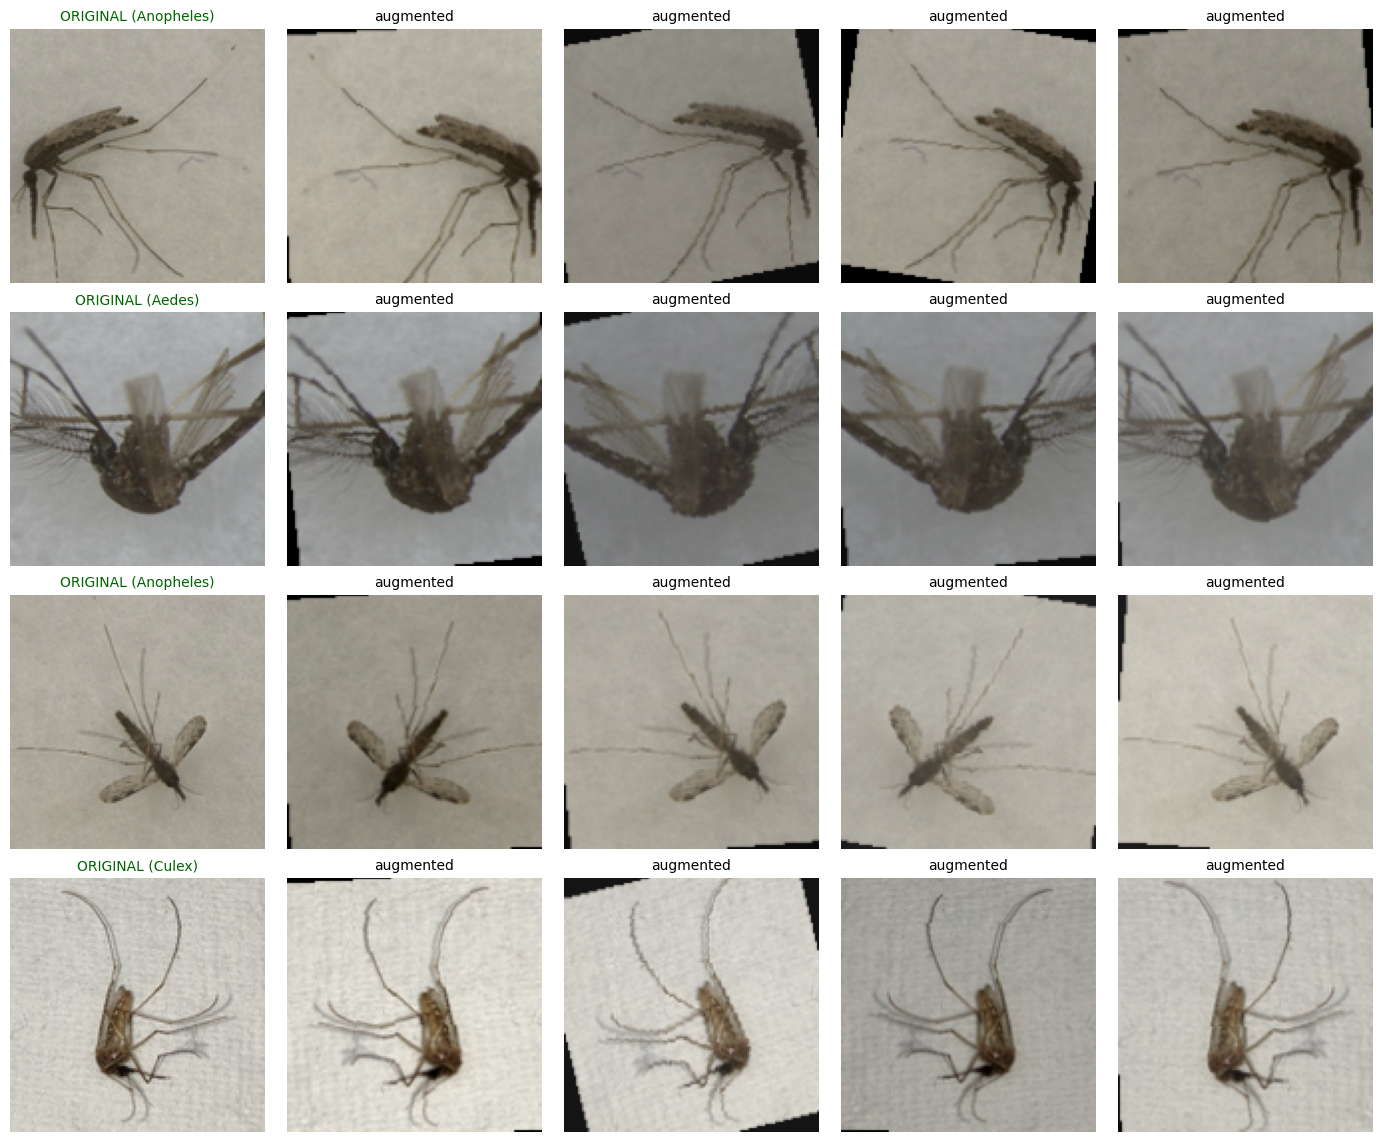

In [47]:
# Cell 2.5 — Show augmentation examples
fig, axes = plt.subplots(4, 5, figsize=(14, 11.5))
sample_idx = np.random.default_rng(SEED).choice(idx_train, 4, replace=False)
for r, j in enumerate(sample_idx):
    base = torch.from_numpy(X[j]).permute(2, 0, 1).float() / 255.0
    axes[r, 0].imshow(base.permute(1, 2, 0).numpy())
    axes[r, 0].set_title(f"ORIGINAL ({CLASS_NAMES[y[j]]})", fontsize=10, color="darkgreen")
    for c in range(1, 5):
        aug = train_aug(base).clamp(0, 1)
        axes[r, c].imshow(aug.permute(1, 2, 0).numpy())
        axes[r, c].set_title("augmented", fontsize=10)
for a in axes.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "augmentation_examples.png", dpi=120)
plt.show()

### ✅ Phase 2 checklist & self-test

- [x] All images resized to 128×128×3 and normalised to [0,1]
- [x] Labels encoded (Aedes 0, Anopheles 1, Culex 2)
- [x] Stratified, **duplicate-aware** train / val / test split + verification
- [x] Augmentation applied to training data only, visualised
- [x] Table with images per split

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **Why resize?** The network expects one fixed input size, and smaller images make training fast.
* **What is normalisation?** Rescaling pixels from 0-255 to 0-1 so numbers are small and consistent, which stabilises optimisation.
* **Why split data?** Training data can't judge generalisation; validation guides decisions; the untouched test set gives an honest final estimate.
* **Why is augmentation useful, and why only on training?** It adds plausible variation so the model can't memorise exact pixels. Evaluation data must stay unmodified to represent real images.
* **Why group by duplicate cluster?** Otherwise near-copies leak across splits and inflate the results.
</details>

---
# 🧠 Phase 3 — Build your own CNN from scratch
*(Roadmap: Days 5–6)*

**Main objective:** design and implement the architecture yourself with PyTorch (no pretrained classifier for the main model).

### The five building blocks

| Component | What it does | Intuition |
|---|---|---|
| **Convolution** (`nn.Conv2d`) | Slides small learnable filters (here 3×3) over the image and records how strongly each pattern appears at every position | Early filters become edge/texture detectors; deeper ones respond to leg stripes, wing veins, body shape |
| **ReLU** | $\max(0,x)$ | Adds *non-linearity*. Without it, stacked layers collapse into one linear operation and can't learn complex patterns |
| **Max-pooling** | Keeps the strongest response in each 2×2 window, halving height & width | Cuts computation, adds tolerance to small shifts |
| **Dropout** | Randomly zeroes a fraction of activations during training | Discourages co-dependence and memorisation → regularisation |
| **Fully-connected layer** (`nn.Linear`) | Combines the final features into 3 class scores (*logits*) | The decision-making part |

### Architecture (v1 – the baseline from the roadmap)

```
Input  3×128×128
Conv(3→32, 3×3, pad 1) → ReLU → MaxPool 2   →  32×64×64
Conv(32→64)            → ReLU → MaxPool 2   →  64×32×32
Conv(64→128)           → ReLU → MaxPool 2   → 128×16×16
Global Average Pooling                      → 128
Dropout → Linear(128→3)                     → 3 logits (Aedes, Anopheles, Culex)
```

**Global average pooling** averages each of the 128 feature maps into a single number. Compared with flattening (128×16×16 = 32,768 values) it needs far fewer parameters, lowering overfitting risk and making the network independent of the exact spatial layout.

**Output:** 3 raw scores (*logits*) per image. `CrossEntropyLoss` applies softmax internally. For human-readable confidence we apply `softmax` ourselves at inference.

The class is **configurable** (`channels`, `dropout`, `use_bn`) because Phase 4 experiments will modify it. `use_bn=True` adds **Batch Normalisation** after each convolution: it re-centres activations, usually making training faster and more stable.

In [ ]:
# Cell 3.1 — The custom CNN
class MosquitoCNN(nn.Module):
    def __init__(self, num_classes=3, channels=(32, 64, 128), dropout=0.5, use_bn=False):
        super().__init__()
        layers, in_c = [], 3
        for out_c in channels:
            layers.append(nn.Conv2d(in_c, out_c, kernel_size=3, padding=1))
            if use_bn:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.ReLU(inplace=False))
            layers.append(nn.MaxPool2d(2))
            in_c = out_c
        self.features = nn.Sequential(*layers)             # convolutional feature extractor
        self.gap = nn.AdaptiveAvgPool2d(1)                 # global average pooling -> (B, C, 1, 1)
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # (B, C)
            nn.Dropout(dropout),
            nn.Linear(in_c, num_classes),                  # (B, 3) logits
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.classifier(x)

def build_model(model_kwargs):
    return MosquitoCNN(**model_kwargs)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

BASELINE_KWARGS = dict(num_classes=3, channels=(32, 64, 128), dropout=0.5, use_bn=False)
model = build_model(BASELINE_KWARGS).to(device)
print(model)
print(f"\nTrainable parameters: {count_params(model):,}")

### Cell 3.2 — Forward-pass test and shape trace
Before training anything we verify the plumbing: pass one real batch through the *untrained* network, print the tensor shape after every layer, and check that the output is `(batch, 3)`. With random weights the predictions should be roughly uniform (≈33% each, loss ≈ $\ln 3 \approx 1.10$). If the initial loss is wildly different, something is wrong.

In [ ]:
# Cell 3.2 — Forward pass test + layer-by-layer shapes
model.eval()
xb, yb = next(iter(val_loader))
xb = xb.to(device)

print(f"{'layer':<28}{'output shape'}")
print("-" * 55)
h = xb
print(f"{'input':<28}{tuple(h.shape)}")
with torch.no_grad():
    for i, layer in enumerate(model.features):
        h = layer(h)
        print(f"features[{i}] {layer.__class__.__name__:<14}{tuple(h.shape)}")
    h = model.gap(h);        print(f"{'global avg pool':<28}{tuple(h.shape)}")
    out = model(xb);         print(f"{'final output (logits)':<28}{tuple(out.shape)}")

assert out.shape == (xb.size(0), 3), "Output must be 3 scores per image"
probs = torch.softmax(out, dim=1)
print("\nExample logits (first image):", out[0].cpu().numpy().round(3))
print("Softmax probabilities        :", probs[0].cpu().numpy().round(3), "(sum =", float(probs[0].sum()), ")")
init_loss = nn.CrossEntropyLoss()(out, yb.to(device)).item()
print(f"Initial loss = {init_loss:.3f}   (random guessing for 3 classes ≈ {np.log(3):.3f})")
print("✅ Forward pass OK")

### Cell 3.3 — Architecture diagram
**Deliverable: architecture diagram.** The diagram below is saved to `results/architecture_diagram.png`.

In [ ]:
# Cell 3.3 — Draw the architecture
from matplotlib.patches import FancyBboxPatch

stages = [("Input\n128×128×3", "#dddddd"),
          ("Conv 3×3\n32 filters\nReLU\nMaxPool\n→ 64×64×32", "#a6cee3"),
          ("Conv 3×3\n64 filters\nReLU\nMaxPool\n→ 32×32×64", "#80b1d3"),
          ("Conv 3×3\n128 filters\nReLU\nMaxPool\n→ 16×16×128", "#5a9bd5"),
          ("Global\nAverage\nPooling\n→ 128", "#fdb462"),
          ("Dropout\n+ Fully\nConnected\n→ 3", "#fb8072"),
          ("Aedes\nAnopheles\nCulex", "#b3de69")]

fig, ax = plt.subplots(figsize=(15, 3.6))
for i, (txt, col) in enumerate(stages):
    ax.add_patch(FancyBboxPatch((i * 2.1, 0), 1.8, 2.2, boxstyle="round,pad=0.05", fc=col, ec="black"))
    ax.text(i * 2.1 + 0.9, 1.1, txt, ha="center", va="center", fontsize=9.5)
    if i < len(stages) - 1:
        ax.annotate("", xy=(i * 2.1 + 2.05, 1.1), xytext=(i * 2.1 + 1.85, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-0.2, len(stages) * 2.1); ax.set_ylim(-0.3, 2.5); ax.axis("off")
ax.set_title("MosquitoVision CNN (baseline v1)", fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "architecture_diagram.png", dpi=150)
plt.show()

### ✅ Phase 3 checklist & self-test

- [x] CNN implemented (`MosquitoCNN(nn.Module)`)
- [x] Architecture printed, parameters counted
- [x] Forward pass on a real batch: output = 3 scores per image
- [x] Diagram saved

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **What does a convolution do?** Applies small learnable filters across the image to detect local patterns; stacking layers builds from edges to shapes to class-specific structures.
* **Why pooling?** Reduces spatial size (less computation), keeps strong activations, adds small-shift tolerance.
* **Why activation functions?** Non-linearity: without them, many layers would equal a single linear layer.
* **What happens with three output scores?** They're logits; softmax turns them into probabilities that sum to 1; the highest is the predicted class and its value is the confidence.
</details>

---
# 🏋️ Phase 4 — Train your CNN and improve it
*(Roadmap: Days 7–9)*

**Main objective:** teach the network to recognise the three genera, *and understand how it behaves while learning*.

### What training means
Initially the weights are random. One training step:

1. a **batch** of images goes through the network → predictions
2. **CrossEntropyLoss** measures how wrong they are
3. **backpropagation** computes how each weight should change to reduce the loss
4. the **Adam optimiser** updates the weights (step size = **learning rate**, 0.001 to start)
5. repeat for every batch; one full pass through the training set = **one epoch**

### Starting hyper-parameters
| Parameter | Value |
|---|---|
| Image size | 128×128 |
| Batch size | 32 |
| Learning rate | 0.001 |
| Max epochs | 30 |
| Optimizer | Adam |
| Loss | CrossEntropyLoss |

### What we record each epoch
training loss, validation loss, training accuracy, validation accuracy (plus learning rate). Plotting them reveals the model's behaviour:

| Pattern | Diagnosis |
|---|---|
| Train acc ↑↑, val acc stagnates/drops, val loss rises | **Overfitting** (memorising) |
| Both accuracies low and flat | **Underfitting** (model too weak / learning rate wrong / too little training) |
| Both curves rise together and plateau close | Healthy generalisation |

### Safeguards built into `fit()`
* **Checkpointing:** the weights with the *lowest validation loss* are saved to Drive (not simply the last epoch).
* **Early stopping:** stop if validation loss hasn't improved for `patience` epochs.
* **Optional LR scheduler** (`ReduceLROnPlateau`): halves the learning rate when validation loss stalls.
* **Experiment log:** every run's configuration and results go into `results/experiment_log.csv`.

### Experiments
| Name | Idea | Purpose |
|---|---|---|
| `exp0_no_augmentation` | baseline model, **no augmentation** | Ablation: shows what augmentation actually buys you (expect more overfitting) |
| `exp1_baseline` | roadmap architecture + augmentation | The reference run |
| `exp2_improved` | + BatchNorm, extra conv block (256 filters), weight decay, LR scheduler | The "at least one improvement" |

The test set is **not touched** here: all decisions use validation data only.

In [ ]:
# Cell 4.1 — Training / evaluation machinery
import copy

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over a loader. If optimizer is given -> training mode, else evaluation mode."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

EXPERIMENTS = []      # experiment log (list of dicts)
HISTORIES   = {}

def fit(name, model, model_kwargs, train_loader, val_loader, lr=1e-3, weight_decay=0.0,
        max_epochs=30, patience=7, use_scheduler=False, candidate=True, notes=""):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
                 if use_scheduler else None)

    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "lr"]}
    best_val_loss, best_epoch, bad_epochs = float("inf"), 0, 0
    ckpt_path = MODELS_DIR / f"{name}_best.pth"
    t0 = time.time()

    print(f"\n=== {name} | params={count_params(model):,} | lr={lr} | wd={weight_decay} | scheduler={use_scheduler} ===")
    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler: scheduler.step(va_loss)

        for k, v in zip(hist.keys(), [tr_loss, va_loss, tr_acc, va_acc, optimizer.param_groups[0]["lr"]]):
            hist[k].append(v)

        improved = va_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss, best_epoch, bad_epochs = va_loss, epoch, 0
            torch.save({"state_dict": model.state_dict(), "model_kwargs": model_kwargs, "class_names": CLASS_NAMES,
                        "img_size": IMG_SIZE, "epoch": epoch, "val_loss": va_loss, "val_acc": va_acc, "name": name}, ckpt_path)
        else:
            bad_epochs += 1

        print(f"Epoch {epoch:02d}/{max_epochs} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.3f} | lr {optimizer.param_groups[0]['lr']:.5f}" + ("  ← best" if improved else ""))
        if bad_epochs >= patience:
            print(f"Early stopping: no validation-loss improvement for {patience} epochs.")
            break

    b = best_epoch - 1
    summary = dict(name=name, notes=notes, params=count_params(model), lr=lr, weight_decay=weight_decay,
                   scheduler=use_scheduler, epochs_run=len(hist["val_loss"]), best_epoch=best_epoch,
                   best_val_loss=round(hist["val_loss"][b], 4), val_acc_at_best=round(hist["val_acc"][b], 4),
                   train_acc_at_best=round(hist["train_acc"][b], 4),
                   train_val_gap=round(hist["train_acc"][b] - hist["val_acc"][b], 4),
                   minutes=round((time.time() - t0) / 60, 2), candidate=candidate, model_kwargs=json.dumps(model_kwargs, default=list))
    EXPERIMENTS.append(summary)
    HISTORIES[name] = hist
    (RESULTS_DIR / f"history_{name}.json").write_text(json.dumps(hist))
    pd.DataFrame(EXPERIMENTS).to_csv(RESULTS_DIR / "experiment_log.csv", index=False)
    return hist, summary

def plot_history(hist, name, save_as=None):
    ep = np.arange(1, len(hist["val_loss"]) + 1)
    best = int(np.argmin(hist["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(ep, hist["train_loss"], label="train loss"); axes[0].plot(ep, hist["val_loss"], label="val loss")
    axes[0].axvline(best, ls="--", c="gray", label=f"best epoch ({best})"); axes[0].set(title=f"{name}: loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(ep, hist["train_acc"], label="train acc"); axes[1].plot(ep, hist["val_acc"], label="val acc")
    axes[1].axvline(best, ls="--", c="gray"); axes[1].set(title=f"{name}: accuracy", xlabel="epoch", ylim=(0, 1.02)); axes[1].legend()
    plt.tight_layout()
    plt.savefig(save_as or RESULTS_DIR / f"training_history_{name}.png", dpi=140)
    plt.show()

print("Training machinery ready.")

### Cell 4.2 — Experiment 0 (ablation): no augmentation
Same baseline network, but the training images are *not* augmented. This isolates the effect of augmentation. Expect training accuracy to climb faster than validation accuracy (a bigger gap = more overfitting). Set `RUN_ABLATION = False` to skip it and save time.

In [ ]:
# Cell 4.2 — Ablation: baseline model without augmentation
RUN_ABLATION = True
if RUN_ABLATION:
    tl0, vl0, _ = make_loaders(augment=False)
    torch.manual_seed(SEED)
    h0, s0 = fit("exp0_no_augmentation", build_model(BASELINE_KWARGS), BASELINE_KWARGS, tl0, vl0,
                 lr=1e-3, candidate=False, notes="baseline CNN, NO augmentation (ablation)")
    plot_history(h0, "exp0_no_augmentation")

### Cell 4.3 — Experiment 1: baseline CNN with augmentation (the first real training run)
This is the roadmap's reference setup. After it finishes, **read the plots**: is validation loss still falling when training stopped (underfitting / needs more epochs), or did it bottom out and rise (overfitting)?

In [ ]:
# Cell 4.3 — Experiment 1: baseline
torch.manual_seed(SEED)
train_loader, val_loader, test_loader = make_loaders(augment=True)
h1, s1 = fit("exp1_baseline", build_model(BASELINE_KWARGS), BASELINE_KWARGS, train_loader, val_loader,
             lr=1e-3, notes="roadmap baseline + augmentation")
plot_history(h1, "exp1_baseline")

### Cell 4.4 — Experiment 2: an improved model
Changes motivated by the diagnosis (adapt them to what *your* curves show):

* **Batch Normalisation** → faster, steadier optimisation.
* **A fourth convolution block (256 filters)** → more capacity to learn discriminative features.
* **Weight decay (L2 regularisation, 1e-4)** → penalises very large weights, reduces overfitting.
* **Learning-rate scheduler** → halves the LR when validation loss stalls, allowing finer convergence.

You can edit `IMPROVED_KWARGS` and re-run to try your own ideas; each run is added to the experiment log.

In [ ]:
# Cell 4.4 — Experiment 2: improved
IMPROVED_KWARGS = dict(num_classes=3, channels=(32, 64, 128, 256), dropout=0.5, use_bn=True)
torch.manual_seed(SEED)
h2, s2 = fit("exp2_improved", build_model(IMPROVED_KWARGS), IMPROVED_KWARGS, train_loader, val_loader,
             lr=1e-3, weight_decay=1e-4, use_scheduler=True, notes="BatchNorm + 4th conv block + weight decay + LR scheduler")
plot_history(h2, "exp2_improved")

### Cell 4.5 — Compare experiments, diagnose overfitting, select the best model
The comparison table reports, for each run's best epoch, the validation loss/accuracy and the **train–validation accuracy gap** (large gap → overfitting). The *candidate* run with the lowest validation loss is copied to `models/best_mosquito_cnn.pth`.

⚠️ Selection uses **validation** data only. The test set stays untouched until Phase 5.

In [ ]:
# Cell 4.5 — Compare runs and pick the best candidate
log = pd.DataFrame(EXPERIMENTS)
display(log[["name", "params", "epochs_run", "best_epoch", "train_acc_at_best", "val_acc_at_best",
             "train_val_gap", "best_val_loss", "minutes", "candidate", "notes"]])

cand = log[log.candidate]
best_row = cand.loc[cand.best_val_loss.idxmin()]
print(f"\n🏆 Selected model: {best_row['name']}  (val loss {best_row.best_val_loss}, val acc {best_row.val_acc_at_best})")

BEST_PATH = MODELS_DIR / "best_mosquito_cnn.pth"
shutil.copy(MODELS_DIR / f"{best_row['name']}_best.pth", BEST_PATH)
plot_history(HISTORIES[best_row["name"]], best_row["name"], save_as=RESULTS_DIR / "training_history.png")
pd.DataFrame(EXPERIMENTS).to_csv(RESULTS_DIR / "experiment_log.csv", index=False)
print("Best checkpoint saved to:", BEST_PATH)

gap = best_row.train_val_gap
if gap > 0.10:
    print(f"\nDiagnosis: train-val gap = {gap:.1%} → signs of OVERFITTING (consider more augmentation, dropout, smaller model).")
elif best_row.val_acc_at_best < 0.7:
    print("\nDiagnosis: low accuracy on both sets → possible UNDERFITTING (try more capacity, more epochs, tune LR).")
else:
    print(f"\nDiagnosis: train-val gap = {gap:.1%} → reasonably healthy generalisation.")

### ✅ Phase 4 checklist & self-test

- [x] First training run completed, history saved (`results/history_*.json`)
- [x] Loss & accuracy plots (`results/training_history*.png`)
- [x] Overfitting/underfitting diagnosed
- [x] At least one improvement tried and logged (`results/experiment_log.csv`)
- [x] Best checkpoint saved (`models/best_mosquito_cnn.pth`)

**Write in your report:** what each run showed, why you made each change, and whether it helped *on validation data*.

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **What is an epoch / a batch?** Epoch = one pass through the full training set. Batch = a small group of images processed together before one weight update.
* **What does backpropagation do?** Computes the gradient of the loss with respect to every weight so the optimiser knows how to change them.
* **Train 99% / val 65%, what does it mean?** Overfitting: memorised training images instead of learning general patterns.
* **Why save the best-validation checkpoint rather than the last epoch?** The last epoch may be more overfitted than an earlier one.
</details>

---
# 📊 Phase 5 — Evaluate the model scientifically
*(Roadmap: Days 10–11)*

**Main objective:** find out whether the model is *actually useful*, not merely whether one number looks good.

> ⚠️ **The test set is used here, once, after model selection.** Do not go back and tweak the model because of what you see below. If you do, the test set becomes a second validation set and the estimate is no longer honest.

### Metrics
| Metric | Question it answers |
|---|---|
| **Accuracy** | What fraction of all predictions are correct? |
| **Precision** (per class) | When the model says *Aedes*, how often is it right? |
| **Recall** (per class) | Of all real *Aedes* images, how many did the model find? |
| **F1-score** | Harmonic mean of precision and recall |
| **Confusion matrix** | *Which* classes get mixed up? |

**Why recall deserves special attention:** missing an *Aedes* (a genus including dengue/Zika/chikungunya vectors) is arguably worse for surveillance than a false alarm. But remember: model errors are **not** measurements of disease risk.

### Error analysis
We collect misclassified images (most *confident* mistakes first, these are the most dangerous and also the best candidates for label errors) and test hypotheses: are errors associated with blurry images? low resolution? Visual similarity between genera?

### Uncertainty handling
A trustworthy tool says "I'm not sure". We pick a **confidence threshold on the validation set** (never on test): the lowest threshold at which predictions the model *accepts* reach a target accuracy while still accepting a reasonable share of images. Below the threshold the app shows *"Uncertain prediction — expert verification recommended."* We then report what this rule does on the test set.

In [ ]:
# Cell 5.1 — Load the selected model and predict on validation and test sets
ckpt = torch.load(BEST_PATH, map_location=device)
best_model = build_model(ckpt["model_kwargs"]).to(device)
best_model.load_state_dict(ckpt["state_dict"])
best_model.eval()
print(f"Loaded '{ckpt['name']}' (best epoch {ckpt['epoch']})")

@torch.no_grad()
def predict_loader(model, loader):
    all_probs, all_y = [], []
    model.eval()
    for xb, yb in loader:
        all_probs.append(torch.softmax(model(xb.to(device)), dim=1).cpu().numpy())
        all_y.append(yb.numpy())
    return np.concatenate(all_probs), np.concatenate(all_y)

val_probs,  val_y  = predict_loader(best_model, val_loader)
test_probs, test_y = predict_loader(best_model, test_loader)
val_pred, test_pred = val_probs.argmax(1), test_probs.argmax(1)
val_conf, test_conf = val_probs.max(1), test_probs.max(1)
print(f"Validation images: {len(val_y)} | Test images: {len(test_y)}")

### Cell 5.2 — Test-set metrics, classification report and confusion matrix
**Deliverables:** accuracy, precision/recall/F1, classification report (`results/classification_report.txt`), confusion matrix (`results/confusion_matrix.png`).

How to read the confusion matrix: rows = true class, columns = predicted class. The diagonal = correct. The right-hand panel is row-normalised, so each diagonal cell is that class's **recall**.

In [ ]:
# Cell 5.2 — Metrics + confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

test_acc = accuracy_score(test_y, test_pred)
report = classification_report(test_y, test_pred, target_names=CLASS_NAMES, digits=3)
print(f"TEST ACCURACY: {test_acc:.3%}  ({int((test_y == test_pred).sum())}/{len(test_y)})\n")
print(report)
(RESULTS_DIR / "classification_report.txt").write_text(f"Model: {ckpt['name']}\nTest accuracy: {test_acc:.4f}\n\n{report}")

cm = confusion_matrix(test_y, test_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, mat, title, fmt in [(axes[0], cm, "Confusion matrix (counts)", "d"), (axes[1], cm_norm, "Row-normalised (= recall)", ".2f")]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
           xlabel="Predicted", ylabel="True", title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > mat.max() / 2 else "black", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

recalls = dict(zip(CLASS_NAMES, cm_norm.diagonal().round(3)))
print("Per-class recall:", recalls)
print(f"⭐ Aedes recall = {recalls['Aedes']:.1%}  → {int(cm[0].sum() - cm[0, 0])} of {int(cm[0].sum())} Aedes test images were missed.")

### Cell 5.3 — Gallery of incorrect predictions
**Deliverable: gallery of incorrect predictions.** Original-resolution photos are shown with true label, predicted label and the model's confidence; files are also copied to `results/incorrect_predictions/`.

Questions to ask while looking:
* Is the mosquito tiny, out of focus or partly hidden?
* Are the distinguishing features visible at all?
* Is the background or lighting unusual compared with typical training images?
* Do two genera simply look alike?
* **Is the *label* possibly wrong?** A confidently wrong prediction can reveal a mislabelled dataset image.

In [ ]:
# Cell 5.3 — Misclassified images
test_rows = data.iloc[idx_test].reset_index(drop=True)
wrong = np.where(test_pred != test_y)[0]
wrong = wrong[np.argsort(-test_conf[wrong])]          # most confident mistakes first
print(f"{len(wrong)} misclassified test images out of {len(test_y)}")

out_dir = RESULTS_DIR / "incorrect_predictions"
for f in out_dir.glob("*"):
    f.unlink()
for rank, k in enumerate(wrong):
    r = test_rows.iloc[k]
    name = f"{rank:03d}_true-{CLASS_NAMES[test_y[k]]}_pred-{CLASS_NAMES[test_pred[k]]}_conf-{test_conf[k]:.2f}.jpg"
    Image.open(r.path).convert("RGB").save(out_dir / name)

show = wrong[:16]
if len(show):
    cols = 4
    rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(14, 3.6 * rows_n))
    axes = np.atleast_2d(axes)
    for a in axes.ravel(): a.axis("off")
    for a, k in zip(axes.ravel(), show):
        a.imshow(Image.open(test_rows.iloc[k].path).convert("RGB"))
        a.set_title(f"true: {CLASS_NAMES[test_y[k]]}\npred: {CLASS_NAMES[test_pred[k]]} ({test_conf[k]:.0%})", fontsize=10, color="crimson")
    plt.suptitle("Most confident mistakes on the test set", fontsize=14)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "incorrect_predictions_gallery.png", dpi=120)
    plt.show()

### Cell 5.4 — Are mistakes linked to image quality?
For every test image we compute **sharpness** (variance of the Laplacian; low = blurry), the **original resolution** and brightness, and compare correctly vs incorrectly classified images. A noticeable difference suggests the model is fragile under poor image quality, which is a concrete finding for your report. (With few errors, differences are noisy: treat them as hints, not proof.)

In [ ]:
# Cell 5.4 — Error analysis vs image quality
from scipy.ndimage import laplace

def sharpness(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((256, 256)), dtype=np.float32)
    return float(laplace(g).var())

test_rows["sharpness"] = [sharpness(p) for p in tqdm(test_rows.path, desc="Sharpness")]
test_rows["pixels_k"]  = test_rows.width * test_rows.height / 1000
test_rows["correct"]   = (test_pred == test_y)
test_rows["confidence"] = test_conf
display(test_rows.groupby("correct")[["sharpness", "pixels_k", "brightness", "confidence"]].agg(["mean", "median"]).round(2))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(test_rows[test_rows.correct].sharpness, test_rows[test_rows.correct].confidence, s=12, alpha=0.4, label="correct")
ax.scatter(test_rows[~test_rows.correct].sharpness, test_rows[~test_rows.correct].confidence, s=25, c="crimson", label="wrong")
ax.set(xscale="log", xlabel="sharpness (log scale)", ylabel="confidence", title="Confidence vs sharpness")
ax.legend(); plt.tight_layout(); plt.show()

# Which genera get confused?
pairs = pd.Series([f"{CLASS_NAMES[t]} → {CLASS_NAMES[p]}" for t, p in zip(test_y[wrong], test_pred[wrong])]).value_counts()
print("\nMost common confusions (true → predicted):")
display(pairs.to_frame("count"))

### Cell 5.5 — Choose the uncertainty threshold **on validation data**
For each candidate threshold $t$, the app *accepts* a prediction if its confidence ≥ $t$ and otherwise says *"Uncertain — expert verification recommended"*. We measure on **validation** data:
* **coverage** = share of images the model is willing to answer
* **accepted accuracy** = accuracy on those accepted images

We choose the **lowest** threshold whose accepted accuracy reaches `TARGET_ACCURACY` while coverage stays ≥ `MIN_COVERAGE`. Lower thresholds keep the tool useful (high coverage); the accuracy target keeps it trustworthy. Change both numbers to match how cautious you want the tool to be.

In [ ]:
# Cell 5.5 — Confidence threshold from validation data
TARGET_ACCURACY = 0.90
MIN_COVERAGE    = 0.50

def threshold_table(conf, pred, true, thresholds):
    rows = []
    for t in thresholds:
        acc_mask = conf >= t
        cov = acc_mask.mean()
        acc = (pred[acc_mask] == true[acc_mask]).mean() if acc_mask.sum() else np.nan
        rows.append((t, cov, acc))
    return pd.DataFrame(rows, columns=["threshold", "coverage", "accepted_accuracy"])

thresholds = np.round(np.arange(0.40, 0.995, 0.01), 2)
val_tt = threshold_table(val_conf, val_pred, val_y, thresholds)

ok_rows = val_tt[(val_tt.accepted_accuracy >= TARGET_ACCURACY) & (val_tt.coverage >= MIN_COVERAGE)]
if len(ok_rows):
    CONF_THRESHOLD = float(ok_rows.threshold.iloc[0])
    print(f"Chosen confidence threshold (from VALIDATION data): {CONF_THRESHOLD:.2f}")
else:
    CONF_THRESHOLD = 0.70
    print("⚠️ No threshold met the target on validation data; falling back to 0.70. Consider lowering TARGET_ACCURACY or improving the model.")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_tt.threshold, val_tt.coverage, label="coverage")
ax.plot(val_tt.threshold, val_tt.accepted_accuracy, label="accuracy of accepted predictions")
ax.axvline(CONF_THRESHOLD, ls="--", c="gray", label=f"chosen = {CONF_THRESHOLD:.2f}")
ax.axhline(TARGET_ACCURACY, ls=":", c="red", lw=1)
ax.set(xlabel="confidence threshold", title="Threshold selection (validation set)"); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confidence_threshold_validation.png", dpi=140); plt.show()

# Report (not tune!) what this rule does on the TEST set
acc_mask = test_conf >= CONF_THRESHOLD
print(f"\nOn the TEST set with threshold {CONF_THRESHOLD:.2f}:")
print(f"  answered (coverage)         : {acc_mask.mean():.1%}")
print(f"  accuracy on answered images : {(test_pred[acc_mask] == test_y[acc_mask]).mean():.1%}")
print(f"  flagged 'expert verification': {(~acc_mask).mean():.1%}")
if (~acc_mask).sum():
    print(f"  accuracy on flagged images  : {(test_pred[~acc_mask] == test_y[~acc_mask]).mean():.1%}  (should be lower - that's the point)")

### Cell 5.6 — Your evaluation write-up
Write the **limitations analysis** for your report. A useful structure (the cell below prints numbers to start from):

1. **Headline result** – test accuracy, per-class precision/recall/F1.
2. **Which class is weakest and why?** (confusion matrix + error gallery).
3. **Failure patterns** – blur, small mosquitoes, backgrounds, look-alike genera, possible label errors.
4. **Uncertainty rule** – coverage vs accuracy trade-off.
5. **What this does *not* show** – no pathogen detection, genus-level only, not Moroccan data, single dataset, camera/background generalisation untested (see Extension C).

In [ ]:
# Cell 5.6 — Auto-draft of the evaluation report (edit it!)
n_wrong = len(wrong)
report_txt = f"""
MOSQUITOVISION AI - EVALUATION REPORT (draft)
=============================================
Selected model : {ckpt['name']} ({count_params(best_model):,} trainable parameters)
Test images    : {len(test_y)}   |   Test accuracy: {test_acc:.2%}   |   Misclassified: {n_wrong}

Per-class recall: {recalls}

Uncertainty rule: confidence < {CONF_THRESHOLD:.2f} -> "Uncertain prediction - expert verification recommended"
  (threshold chosen on validation data; target accepted accuracy {TARGET_ACCURACY:.0%}, min coverage {MIN_COVERAGE:.0%})
  Test coverage: {(test_conf >= CONF_THRESHOLD).mean():.1%}

LIMITATIONS
 1. Genus-level labels only; exact species are not identified.
 2. Identification is not pathogen detection.
 3. Dataset merges several sources and is not representative of Moroccan mosquito populations.
 4. One random (duplicate-aware) split: results come from the same distribution as training data.
 5. Behaviour on different cameras, backgrounds, lighting and blur is untested here (see Extension C).

MY ANALYSIS (write here):
 - Weakest class and likely reason: ...
 - Patterns in the misclassified images: ...
 - Possible label errors found: ...
"""
print(report_txt)
(RESULTS_DIR / "evaluation_report.txt").write_text(report_txt)

### ✅ Phase 5 checklist & self-test

- [x] Test-set evaluation (once, after model selection)
- [x] Confusion matrix, precision, recall, F1, classification report
- [x] Gallery of incorrect predictions + quality analysis
- [x] Uncertainty threshold chosen on validation data
- [x] Written limitations

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **Why isn't accuracy enough?** It hides which classes fail. A model could look good overall but miss most *Aedes*.
* **Precision vs recall?** Precision: of the images predicted as X, how many truly are X. Recall: of all true X images, how many were found.
* **Why choose the threshold on validation data?** Choosing it on test data would tune the system to the test set and make the reported result optimistic.
* **Does 95% test accuracy mean it will work in the field?** No: it only shows performance on data like the test set.
</details>

---
# 🖥️ Phase 6 — Build the final MosquitoVision application
*(Roadmap: Days 12–14)*

**Main objective:** turn the trained network into something another person can use.

### Pipeline of the application
```
User uploads photo → convert to RGB → resize 128×128 → divide by 255 → CNN → softmax
    → predicted genus + confidence
    → confidence ≥ threshold ?  show result + public-health context
                         else   ⚠ "Uncertain prediction — expert verification recommended."
    → add to session history
```
**Critical rule:** inference must use *exactly* the same preprocessing as training (same size, same RGB conversion, same /255). Any mismatch silently degrades accuracy.

### What this phase does
1. Saves everything the app needs: weights + an **`inference_config.json`** (class names, image size, model hyper-parameters, **confidence threshold chosen in Phase 5**).
2. Writes `app/model.py` (the same architecture), `app/app.py` (Streamlit UI), `requirements.txt` and `README.md`.
3. Tests the inference function **inside the notebook** on test images.
4. Gives an optional cell to **launch the Streamlit app from Colab** through a public tunnel.

The app shows: upload widget, prediction, confidence bar, short **public-health context** for the predicted genus, an **uncertainty warning**, and a **session history** of previous uploads.

In [ ]:
# Cell 6.1 — Save the model and the inference configuration
import shutil

inference_config = {
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "model_kwargs": {k: (list(v) if isinstance(v, tuple) else v) for k, v in ckpt["model_kwargs"].items()},
    "confidence_threshold": CONF_THRESHOLD,
    "weights_file": "best_mosquito_cnn.pth",
    "model_name": ckpt["name"],
    "test_accuracy": round(float(test_acc), 4),
}
(MODELS_DIR / "inference_config.json").write_text(json.dumps(inference_config, indent=2))

# Plain state_dict for the app (smaller, no extra metadata needed)
torch.save(best_model.state_dict(), MODELS_DIR / "best_mosquito_cnn_weights.pth")
inference_config["weights_file"] = "best_mosquito_cnn_weights.pth"
(MODELS_DIR / "inference_config.json").write_text(json.dumps(inference_config, indent=2))
print(json.dumps(inference_config, indent=2))

In [ ]:
# Cell 6.2 — Write model.py (same architecture as in Phase 3)
(APP_DIR / "model.py").write_text("""import torch.nn as nn


class MosquitoCNN(nn.Module):
    def __init__(self, num_classes=3, channels=(32, 64, 128), dropout=0.5, use_bn=False):
        super().__init__()
        layers, in_c = [], 3
        for out_c in channels:
            layers.append(nn.Conv2d(in_c, out_c, kernel_size=3, padding=1))
            if use_bn:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.ReLU(inplace=False))
            layers.append(nn.MaxPool2d(2))
            in_c = out_c
        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(in_c, num_classes))

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))
""")
print("Wrote", APP_DIR / "model.py")

### Cell 6.3 — Write the Streamlit app (`app/app.py`)
Features: image upload · identical preprocessing · CNN prediction · confidence display · public-health context · uncertainty warning · session history. The model is loaded once and cached (`st.cache_resource`).

In [ ]:
# Cell 6.3 — Write app.py
(APP_DIR / "app.py").write_text("""import json
import os
from pathlib import Path

import numpy as np
import streamlit as st
import torch
from PIL import Image

from model import MosquitoCNN

HERE = Path(__file__).resolve().parent
MODEL_DIR = Path(os.environ.get("MODEL_DIR", HERE.parent / "models"))
if not (MODEL_DIR / "inference_config.json").exists():
    MODEL_DIR = HERE            # fallback: files next to app.py

CONTEXT = {
    "Aedes": "Some Aedes species (for example Aedes aegypti and Aedes albopictus) can transmit dengue, Zika, chikungunya and yellow fever.",
    "Anopheles": "Female Anopheles mosquitoes are the vectors of the parasites that cause human malaria.",
    "Culex": "Some Culex species can transmit West Nile virus and Japanese encephalitis virus.",
}
DISCLAIMER = ("Genus identification alone cannot establish whether this specimen is infected, "
              "and this prototype does not identify exact species. Expert verification is recommended for any surveillance decision.")


@st.cache_resource
def load_model():
    cfg = json.loads((MODEL_DIR / "inference_config.json").read_text())
    kwargs = dict(cfg["model_kwargs"])
    kwargs["channels"] = tuple(kwargs["channels"])
    model = MosquitoCNN(**kwargs)
    model.load_state_dict(torch.load(MODEL_DIR / cfg["weights_file"], map_location="cpu"))
    model.eval()
    return model, cfg


def preprocess(img, size):
    # IDENTICAL to training: RGB -> resize -> divide by 255
    img = img.convert("RGB").resize((size, size), Image.LANCZOS)
    arr = np.asarray(img, dtype=np.uint8)
    return torch.from_numpy(arr).permute(2, 0, 1).float().div(255.0).unsqueeze(0)


def predict(model, cfg, img):
    with torch.no_grad():
        probs = torch.softmax(model(preprocess(img, cfg["img_size"])), dim=1)[0].numpy()
    k = int(probs.argmax())
    return cfg["class_names"][k], float(probs[k]), probs


st.set_page_config(page_title="MosquitoVision AI", page_icon="🦟", layout="centered")
st.title("🦟 MosquitoVision AI")
st.caption("Research prototype: CNN-based mosquito genus identification (Aedes / Anopheles / Culex).")

model, cfg = load_model()
threshold = cfg["confidence_threshold"]

if "history" not in st.session_state:
    st.session_state.history = []

uploaded = st.file_uploader("Upload a mosquito photograph", type=["jpg", "jpeg", "png", "webp", "bmp"])

if uploaded is not None:
    img = Image.open(uploaded)
    label, conf, probs = predict(model, cfg, img)
    st.image(img, caption=uploaded.name, use_container_width=True)

    if conf >= threshold:
        st.success(f"Predicted group: {label}")
    else:
        st.warning("Uncertain prediction - expert verification recommended.")
        st.write(f"Most likely group (low confidence): {label}")

    st.metric("Confidence", f"{conf:.1%}")
    st.caption(f"Confidence threshold: {threshold:.0%} (chosen on validation data)")
    for name, p in zip(cfg["class_names"], probs):
        st.progress(float(p), text=f"{name}: {p:.1%}")

    st.subheader("Public-health context")
    st.write(CONTEXT[label])
    st.info(DISCLAIMER)

    entry = (uploaded.name, label, conf, conf >= threshold)
    if not st.session_state.history or st.session_state.history[-1][0] != entry[0] or st.session_state.history[-1][2] != entry[2]:
        thumb = img.convert("RGB").copy()
        thumb.thumbnail((120, 120))
        st.session_state.history.append((uploaded.name, label, conf, conf >= threshold, thumb))

st.divider()
st.subheader("Prediction history (this session)")
if not st.session_state.history:
    st.write("No images analysed yet.")
for name, label, conf, sure, thumb in reversed(st.session_state.history):
    c1, c2 = st.columns([1, 4])
    c1.image(thumb)
    c2.write(f"{name}: {label} ({conf:.0%}) " + ("" if sure else "- UNCERTAIN, expert verification recommended"))
""")
print("Wrote", APP_DIR / "app.py")

In [ ]:
# Cell 6.4 — requirements.txt and README.md
(PROJECT_DIR / "requirements.txt").write_text("streamlit>=1.30\ntorch>=2.0\ntorchvision>=0.15\npillow>=10.0\nnumpy>=1.24\n")

readme = f"""# MosquitoVision AI

CNN-based mosquito genus identification (Aedes / Anopheles / Culex), built from scratch in PyTorch.
Research prototype for public-health surveillance support.

## Results (held-out test set)
- Model: {ckpt['name']}
- Test accuracy: {test_acc:.2%}
- Per-class recall: {recalls}
- Uncertainty rule: confidence < {CONF_THRESHOLD:.2f} -> "expert verification recommended"

## Dataset
MosqVision-3K - Masud (2024), Zenodo, DOI 10.5281/zenodo.14238701
https://zenodo.org/records/14238701
The dataset is NOT included in this repository. Download it from Zenodo (the notebook does this automatically)
and check its reuse terms before redistributing any images.

## Run the application
pip install -r requirements.txt
cd app
streamlit run app.py

## Scientific limitations
1. Identification is not pathogen detection.
2. Genus-level labels only, not exact species.
3. A prediction is not a confirmed identification; experts must verify uncertain cases.
4. The training data is not representative of Moroccan mosquito populations.
5. Good test accuracy does not prove real-world effectiveness; other cameras/backgrounds must be tested.

## References
1. WHO - Vector-borne diseases fact sheet.
2. Pise et al. (2022) - Dataset of Vector Mosquito Images, Data in Brief.
3. Masud (2024) - MosqVision-3K, Zenodo, 10.5281/zenodo.14238701.
4. Nolte et al. (2024) - Robust mosquito species identification from diverse body and wing images using deep learning, Parasites & Vectors.
"""
(PROJECT_DIR / "README.md").write_text(readme)
print("Wrote requirements.txt and README.md in", PROJECT_DIR)

### Cell 6.5 — Test the inference pipeline inside the notebook
This reproduces exactly what the app does: open a file → RGB → resize → /255 → CNN → softmax → apply threshold. We run it on a handful of **test-set** images (never used for training or model selection). To try your own photo, set `MY_IMAGE` to a path in Drive.

In [ ]:
# Cell 6.5 — Inference function (same logic as app.py) + demo
def predict_image(path_or_pil, model=best_model, threshold=CONF_THRESHOLD):
    img = path_or_pil if isinstance(path_or_pil, Image.Image) else Image.open(path_or_pil)
    arr = np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS), dtype=np.uint8)
    x = torch.from_numpy(arr).permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    k = int(probs.argmax())
    return dict(label=CLASS_NAMES[k], confidence=float(probs[k]), certain=bool(probs[k] >= threshold), probs=probs)

demo = test_rows.sample(6, random_state=1)
fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
for ax, (_, r) in zip(axes, demo.iterrows()):
    res = predict_image(r.path)
    ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
    verdict = res["label"] if res["certain"] else "UNCERTAIN - expert\nverification recommended"
    ax.set_title(f"true: {r.label}\n{verdict} ({res['confidence']:.0%})", fontsize=9,
                 color="green" if (res["certain"] and res["label"] == r.label) else ("orange" if not res["certain"] else "crimson"))
plt.tight_layout(); plt.show()

MY_IMAGE = None   # e.g. "/content/drive/MyDrive/my_mosquito.jpg"
if MY_IMAGE:
    print(predict_image(MY_IMAGE))

### Cell 6.6 — (Optional) Launch the Streamlit app from Colab
Colab has no public URL, so we expose the app through a **localtunnel**:

1. Run the cell below. It installs Streamlit + localtunnel and starts the app in the background.
2. It prints a **tunnel password** (this machine's public IP) and a URL like `https://xxxx.loca.lt`.
3. Open the URL and paste the IP as the password.

Stop it by interrupting the cell / restarting the runtime. For a permanent deployment, push the repo to GitHub and use Streamlit Community Cloud (you'll need to include the small `models/` weights file but **not** the dataset).

In [ ]:
# Cell 6.6 — Run Streamlit through a public tunnel (optional)
!pip -q install streamlit
!npm install -q -g localtunnel

import subprocess, time, urllib.request
subprocess.run("pkill -f streamlit", shell=True)
subprocess.Popen(f"cd '{APP_DIR}' && streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1", shell=True)
time.sleep(8)
print("Tunnel password (your public IP):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
!npx localtunnel --port 8501

### ✅ Phase 6 checklist & self-test

- [x] Trained model saved (`models/best_mosquito_cnn.pth`, `best_mosquito_cnn_weights.pth`, `inference_config.json`)
- [x] Streamlit app written (`app/app.py`, `app/model.py`)
- [x] Upload → preprocessing → prediction → confidence → public-health context
- [x] Uncertainty warning + session history
- [x] Tested on images not used for training
- [x] `README.md` and `requirements.txt`

<details><summary><b>Can you answer these? (click to compare)</b></summary>

* **Why must the app preprocess exactly like training?** The network learnt on 128×128 RGB images scaled to [0,1]; any other input format changes what it "sees".
* **Why show an uncertainty message?** A wrong confident answer is worse than an honest "I'm not sure".
* **What can the app NOT tell you?** Species, infection status, or anything about mosquitoes that look unlike the training data.
</details>

---
# 🌟 Optional extensions
Not required for the first working version. Run them if you finish early.

## Extension A — Grad-CAM: what does the CNN look at?
**Grad-CAM** highlights the image regions that most increased the score of the predicted class. It answers: does the CNN look at the *mosquito* (body, legs, wings) or at irrelevant *background* (a ruler, a leaf, a tray)? If the heat-map sits on the background, the model is using a shortcut and its accuracy can't be trusted.

How: take the feature maps of the last convolution block, weight each map by the average gradient of the class score with respect to it, sum, apply ReLU and upsample to the image size.

In [ ]:
# Extension A — Grad-CAM
import matplotlib.cm as cm_mod

def grad_cam(model, x, target=None):
    model.eval()
    target_layer = [m for m in model.features if isinstance(m, nn.ReLU)][-1]      # last conv block's ReLU
    store = {}
    def fwd_hook(module, inp, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))
    handle = target_layer.register_forward_hook(fwd_hook)
    out = model(x)
    cls = int(out.argmax(1).item()) if target is None else target
    model.zero_grad()
    out[0, cls].backward()
    handle.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, cls

sel = np.random.default_rng(3).choice(len(idx_test), 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for c, s in enumerate(sel):
    j = idx_test[s]
    img_t = torch.from_numpy(X[j]).permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(device)
    cam, cls = grad_cam(best_model, img_t)
    axes[0, c].imshow(X[j]); axes[0, c].axis("off"); axes[0, c].set_title(f"true: {CLASS_NAMES[y[j]]}", fontsize=10)
    heat = cm_mod.jet(cam)[..., :3]
    axes[1, c].imshow(0.55 * (X[j] / 255.0) + 0.45 * heat); axes[1, c].axis("off")
    axes[1, c].set_title(f"pred: {CLASS_NAMES[cls]}", fontsize=10, color="green" if cls == y[j] else "crimson")
plt.suptitle("Grad-CAM: red = regions that drove the prediction", fontsize=14)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "gradcam_examples.png", dpi=120); plt.show()

## Extension B — Benchmark against a pretrained ResNet18
Your custom CNN stays the **main** model. A pretrained ResNet18 (ImageNet weights, fine-tuned) is a *benchmark* to see how a standard architecture compares in accuracy, parameters and training time. The wrapper adds ImageNet mean/std normalisation internally, so it uses the same data loaders as everything else. Set `RUN_EXT_B = True` to run it (needs internet access for the weights).

In [ ]:
# Extension B — ResNet18 benchmark
RUN_EXT_B = False
if RUN_EXT_B:
    import torchvision

    class NormalizedResNet(nn.Module):
        def __init__(self, num_classes=3):
            super().__init__()
            self.net = torchvision.models.resnet18(weights="DEFAULT")
            self.net.fc = nn.Linear(self.net.fc.in_features, num_classes)
            self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
            self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        def forward(self, x):
            return self.net((x - self.mean) / self.std)

    torch.manual_seed(SEED)
    hb, sb = fit("extB_resnet18", NormalizedResNet(), {"arch": "resnet18"}, train_loader, val_loader,
                 lr=3e-4, weight_decay=1e-4, max_epochs=12, patience=4, use_scheduler=True, candidate=False,
                 notes="pretrained ResNet18 benchmark")
    plot_history(hb, "extB_resnet18")
    display(pd.DataFrame(EXPERIMENTS)[["name", "params", "best_epoch", "val_acc_at_best", "best_val_loss", "minutes"]])

## Extension C — Real-world robustness test
Published research reports that mosquito classifiers can lose accuracy when the *camera* differs from the training camera. We can't change the camera here, but we can **simulate** degraded conditions on the **test set** (blur, low light, noise, rotation, small objects). A large accuracy drop under a mild perturbation is a finding about fragility, and a reason to collect field photos before any deployment. (Simulated perturbations are *not* a substitute for photos from real, different cameras.)

In [ ]:
# Extension C — Perturbation robustness on the test set
import torchvision.transforms.functional as TF

perturbations = {
    "none":                lambda x: x,
    "blur (sigma 2)":      lambda x: TF.gaussian_blur(x, kernel_size=9, sigma=2.0),
    "blur (sigma 4)":      lambda x: TF.gaussian_blur(x, kernel_size=15, sigma=4.0),
    "darker (x0.5)":       lambda x: (x * 0.5).clamp(0, 1),
    "brighter (x1.6)":     lambda x: (x * 1.6).clamp(0, 1),
    "low contrast":        lambda x: ((x - 0.5) * 0.5 + 0.5).clamp(0, 1),
    "gaussian noise":      lambda x: (x + 0.08 * torch.randn_like(x)).clamp(0, 1),
    "rotate 30°":          lambda x: TF.rotate(x, 30),
    "rotate 90°":          lambda x: TF.rotate(x, 90),
    "zoom out (mosquito smaller)": lambda x: F.pad(F.interpolate(x, scale_factor=0.5, mode="bilinear"), (32, 32, 32, 32), value=0.5),
}

@torch.no_grad()
def accuracy_under(fn):
    correct = 0
    for xb, yb in test_loader:
        correct += (best_model(fn(xb.to(device))).argmax(1).cpu() == yb).sum().item()
    return correct / len(test_y)

rob = pd.DataFrame({"test accuracy": {k: accuracy_under(f) for k, f in perturbations.items()}})
rob["change vs clean"] = rob["test accuracy"] - rob.loc["none", "test accuracy"]
display(rob.style.format("{:.3f}"))
ax = rob["test accuracy"].plot.barh(figsize=(7, 4.5), color="#5a9bd5"); ax.invert_yaxis()
ax.set(xlim=(0, 1), title="Accuracy under simulated image degradations")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "robustness.png", dpi=140); plt.show()
rob.to_csv(RESULTS_DIR / "robustness.csv")

## Extension D — Public-health surveillance dashboard (notes only)
A dashboard of identified groups by place and time **requires properly labelled, geographically documented observations**, which this dataset does not provide. Do **not** invent locations, and do **not** treat model predictions as confirmed field observations. A responsible future version would:
1. collect photos with consent, time stamps and location metadata,
2. label them by entomologists,
3. validate the CNN on this local data,
4. display model predictions as *"unverified, model-suggested"* until an expert confirms them.

---
# 🏁 Wrap-up
### Project deliverables
| Deliverable | Where |
|---|---|
| Dataset analysis | Phase 1 · `results/dataset_summary.txt`, `sample_gallery.png`, `class_distribution_raw.png` |
| Preprocessing pipeline | Phase 2 · `results/split_manifest.csv`, `augmentation_examples.png` |
| Custom CNN | Phase 3 · `MosquitoCNN`, `architecture_diagram.png` |
| Training notebook | this file |
| Experiment log | Phase 4 · `results/experiment_log.csv`, `training_history*.png` |
| Evaluation report | Phase 5 · `classification_report.txt`, `confusion_matrix.png`, `evaluation_report.txt`, `incorrect_predictions/` |
| Grad-CAM (optional) | Extension A · `gradcam_examples.png` |
| Streamlit application | Phase 6 · `app/app.py` |
| GitHub repo files | `README.md`, `requirements.txt` |

### Learning checklist
- [ ] Image representation and RGB  - [ ] Resizing and normalisation  - [ ] Train / validation / test sets
- [ ] Convolution and filters  - [ ] ReLU and pooling  - [ ] CNN architecture
- [ ] Loss functions and optimisers  - [ ] Epochs, batches, backpropagation  - [ ] Overfitting and regularisation
- [ ] Precision, recall, F1  - [ ] Confusion matrices  - [ ] Model inference and deployment

### 📌 For GitHub
Upload the notebook, `app/`, `models/` (small weights file), `results/` plots, `README.md`, `requirements.txt`. **Do not upload the dataset ZIP or the extracted images.** Include the dataset citation, link and download instructions instead, and check the dataset's reuse terms before redistributing any images.

### References
1. WHO, *Vector-borne diseases* fact sheet: https://www.who.int/en/news-room/fact-sheets/detail/vector-borne-diseases
2. Pise et al. (2022), *Dataset of Vector Mosquito Images*, Data in Brief: https://doi.org/10.1016/j.dib.2022.108573
3. Masud (2024), *MosqVision-3K*, Zenodo: https://zenodo.org/records/14238701
4. Nolte et al. (2024), *Robust mosquito species identification from diverse body and wing images using deep learning*, Parasites & Vectors: https://doi.org/10.1186/s13071-024-06459-3

In [ ]:
# Final cell — list everything saved in Google Drive
for folder in [DATA_DIR, MODELS_DIR, RESULTS_DIR, APP_DIR]:
    print(f"\n📁 {folder}")
    for f in sorted(folder.glob("*")):
        if f.is_file():
            print(f"    {f.name:<45} {f.stat().st_size/1e6:8.2f} MB")
        else:
            print(f"    {f.name}/")